In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tabular_study import clean_diagnose, one_hot_encode

In [3]:
dataset_path = "/data/mvillota/EmbryoDev/Datasets/Processed/Oslo_viability/original.xlsx"
df = pd.read_excel(dataset_path, sheet_name="Morula_Blast_nov")

In [4]:
df

,OPU_ID_Number (corresponds to treatment id) fripro,,.1,Embryo_id,Selection,HCG Test,DET/TET,number of oocytes,IVF/ICSI,Age,...,USRVAR_3_DUC - Time,USRVAR_3_DUC - Value,USRVAR_4_Reversert - Time,USRVAR_4_Reversert - Value,USRVAR_5_Early cleavage - Time,USRVAR_5_Early cleavage - Value,Well key,.4,Tse,frame_hour
0,84452.0,372.1,x,1,Transfer,neg,NaN,4,ivf,34.0,...,NaN,NaN,NaN,NaN,NaN,NaN,516.0,889.0,19.29768,3.003053
1,84452.0,372.2,NaN,2,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,516.0,889.0,19.29768,3.003053
2,84452.0,372.3,NaN,3,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,516.0,889.0,19.29768,3.003053
3,84452.0,372.4,NaN,4,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,516.0,889.0,19.29768,3.003053
4,77144.0,373.1,NaN,1,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,351.0,600.0,18.81168,4.004048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3382,79419.0,836.2,x,2,Transfer,negativ,NaN,6,icsi,35.0,...,NaN,NaN,NaN,NaN,NaN,NaN,974.0,1733.0,0.24192,8.533403
3383,79419.0,836.3,NaN,3,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,974.0,1733.0,0.24192,8.533403
3384,79419.0,836.4,NaN,4,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,974.0,1733.0,0.24192,8.533403
3385,79419.0,836.5,NaN,5,Avoid,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,974.0,1733.0,0.24192,8.533403


## Preprocessing 

In [64]:
implantation = {
    'mi': None,
    'hcg testpositiv': 1,
    'pos': 1,
    'positiv': 1,
    'biokjemisk': 1,       
    'neg': 0,
    'negativ': 0,
    'negative': 0,
    'negativ (står positiv i lf uten mer informasjon, men neg. i sys.x.)': 0
}
df['HCG Test'] = df['HCG Test'].map(implantation)

In [65]:
df.dropna(subset=["HCG Test"], inplace=True)
df.reset_index(drop=True, inplace=True)

In [66]:
for row in df.itertuples():
    if pd.isna(row._asdict()['t2']):
        print(row._asdict())
        df = df.drop(index=row.Index, inplace=False)
df = df.reset_index(drop=True)

{'Index': 141, '_1': 82207.0, '_2': '512.11', '_3': 'x', 'Embryo_id': 1, 'Selection': 'Transfer', '_6': 0.0, '_7': nan, '_8': nan, '_9': nan, 'Age': nan, 'Age_mann': nan, '_12': nan, 'Diagnose': nan, 'smoke': nan, 'snus': nan, '_16': nan, '_17': nan, '_18': nan, '_19': nan, 'sex': nan, 'week': nan, 'lenght': nan, 'weight': nan, 'complications': nan, '_25': 43158.46365, 'Fertilization': 43158.44097, 'Runs': 4, '_28': nan, 'ID': 'D2018.02.27_S01059_I0426_D', '_30': 43158.44354, 'Transferred': 1, 'Well': 1, 'tPB2': nan, 'tPNa': nan, 'tPNf': nan, 't2': nan, 't3': nan, 't4': nan, 't5': nan, 't6': nan, 't7': nan, 't8': nan, '_43': nan, 'tSC': nan, 'tM': nan, 'tSB': nan, 'tB': nan, 'tEB': nan, 'tHB': nan, '_50': nan, '_51': nan, '_52': nan, '_53': nan, '_54': nan, '_55': nan, '_56': nan, '_57': nan, '_58': nan, '_59': nan, '_60': nan, '_61': nan, '_62': nan, '_63': nan, '_64': nan, '_65': nan, '_66': nan, '_67': nan, '_68': nan, '_69': nan, '_70': nan, '_71': nan, '_72': nan, '_73': nan, '_74

In [67]:
len(df)

460

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 79 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   OPU_ID_Number (corresponds to treatment id) fripro  453 non-null    float64
 1                                                       460 non-null    object 
 2    .1                                                 456 non-null    object 
 3   Embryo_id                                           460 non-null    int64  
 4   Selection                                           460 non-null    object 
 5   HCG Test                                            460 non-null    float64
 6   DET/TET                                             11 non-null     object 
 7   number of oocytes                                   455 non-null    object 
 8   IVF/ICSI                                            456 non-null    object 
 9  

In [69]:
df['Fetal Heart Beat']= df['Fetal Heart Beat'].fillna(0)

In [70]:
df['Fetal Heart Beat'].value_counts()

Fetal Heart Beat
0     273
1     184
mi      3
Name: count, dtype: int64

In [71]:
df['Fetal Heart Beat']= df['Fetal Heart Beat'].fillna(0)
df.loc[df['Fetal Heart Beat'] == 'mi', 'Fetal Heart Beat'] = None

In [72]:
drop_column = ['OPU_ID_Number (corresponds to treatment id) fripro', ' ', ' .1', 'Embryo_id',' .3','Gestational Sacs', 
               'sex', 'week', 'lenght', 'weight', ' .2', 'complications','End Time', 'Fertilization', 'Runs', 'Slide Description', #'ID', 'Start Time', 
               'Transferred','tPB2', 'tPNa', 'tPNf', 'End Time', 'Fertilization', 'Runs', 'Slide Description',#'Well', 
               'Well key','Selection', 'DET/TET','Fragmentation - Time', 'Irregular Division - Time','Multi Nucleation - Time' ,
               'Pronuclei - Time', 'Inner Cell Mass - Time', 'Trophectoderm Evaluation - Time','USRVAR_1_Multinucleation - Time', 'USRVAR_2_Unormal oocytt - Time', 
               'USRVAR_3_DUC - Time', 'USRVAR_4_Reversert  - Time', 'USRVAR_5_Early cleavage - Time',' .4', 'Tse', 'frame_hour'
               ]
df = df.drop(columns=drop_column)

In [73]:
for column in df.columns:
    print(f"{column}: {df[column].isna().sum()} nan values")

HCG Test: 0 nan values
number of oocytes: 5 nan values
IVF/ICSI: 4 nan values
Age: 4 nan values
Age_mann: 4 nan values
Diagnose: 5 nan values
smoke: 24 nan values
snus: 25 nan values
Abortion Comment: 416 nan values
Fetal Heart Beat: 3 nan values
ID: 0 nan values
Start Time: 0 nan values
Well: 0 nan values
t2: 0 nan values
t3: 1 nan values
t4: 1 nan values
t5: 3 nan values
t6: 3 nan values
t7: 7 nan values
t8: 30 nan values
t9+: 31 nan values
tSC: 207 nan values
tM: 19 nan values
tSB: 106 nan values
tB: 200 nan values
tEB: 320 nan values
tHB: 458 nan values
Blastomere Size - Time: 232 nan values
Blastomere Size - Value: 232 nan values
Fragmentation - Value: 28 nan values
Irregular Division - Value: 460 nan values
Multi Nucleation - Value: 370 nan values
Nuclei - Time: 34 nan values
Nuclei - Value: 34 nan values
Pronuclei - Value: 146 nan values
Inner Cell Mass - Value: 288 nan values
Trophectoderm Evaluation - Value: 285 nan values
USRVAR_1_Multinucleation - Value: 355 nan values
USRVA

In [74]:
columns_drop = ['Abortion Comment', 'tEB','tHB', 'Irregular Division - Value',
                'USRVAR_1_Multinucleation - Value',  'USRVAR_2_Unormal oocytt - Value',  'USRVAR_3_DUC - Value',
                 'USRVAR_4_Reversert  - Value',  'USRVAR_5_Early cleavage - Value', 'Blastomere Size - Time', 'Nuclei - Time',
                'USRVAR_2_Unormal oocytt - Value','USRVAR_3_DUC - Value', 'USRVAR_4_Reversert  - Value', 'USRVAR_5_Early cleavage - Value']
df = df.drop(columns=columns_drop)

In [75]:
smoke_map = {
    # --- No smoker ---
    '0': 0,
    '0': 0,
    'nei': 0,
    
    # --- Smokers ---
    '3': 1,
    '5': 1,
    '0-5/d': 1,
    '1-5': 1,
    '1 (0-5/d)': 1,
    '1 (ikke daglig)': 1,

    # --- Heavy Smokers ---
    '1-10/d': 2,
    '10/d': 2,
    '1 (6-15/d)': 2,
    '1 (1-10/d)': 2,
    
    # --- noise ---
    'mi': None  # Se convertirá en NaN en Pandas
}
df['smoke'] = df['smoke'].map(smoke_map)

In [76]:
snus_map = {
    # --- No snus (0) ---
    '0': 0,
    'nei': 0,
    
    # --- snus (1) ---
    '1': 1,
    '2': 1,
    '3': 1,
    '5': 1,
    '4-5pk/d': 1,
    '1 (en sjelden gang)': 1,  
    '1 (0-1d/v)': 1,
    '1-2 d/v': 1,
    '1(slutter)': 1,           
    
    # --- Noise ---
    'mi': None                 
}
df['snus'] = df['snus'].map(snus_map)

In [77]:
len(df)

460

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 31 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HCG Test                          460 non-null    float64
 1   number of oocytes                 455 non-null    object 
 2   IVF/ICSI                          456 non-null    object 
 3   Age                               456 non-null    float64
 4   Age_mann                          456 non-null    float64
 5   Diagnose                          455 non-null    object 
 6   smoke                             268 non-null    float64
 7   snus                              270 non-null    float64
 8   Fetal Heart Beat                  457 non-null    object 
 9   ID                                460 non-null    object 
 10  Start Time                        460 non-null    float64
 11  Well                              460 non-null    int64  
 12  t2      

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 31 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HCG Test                          460 non-null    float64
 1   number of oocytes                 455 non-null    object 
 2   IVF/ICSI                          456 non-null    object 
 3   Age                               456 non-null    float64
 4   Age_mann                          456 non-null    float64
 5   Diagnose                          455 non-null    object 
 6   smoke                             268 non-null    float64
 7   snus                              270 non-null    float64
 8   Fetal Heart Beat                  457 non-null    object 
 9   ID                                460 non-null    object 
 10  Start Time                        460 non-null    float64
 11  Well                              460 non-null    int64  
 12  t2      

In [80]:
df['Fetal Heart Beat']

0      0
1      0
2      0
3      0
4      1
      ..
455    0
456    1
457    0
458    0
459    0
Name: Fetal Heart Beat, Length: 460, dtype: object

### Transform Diagnose into categorical one hot encoder.
we have seen that there is no effect. 

In [81]:
df

,HCG Test,number of oocytes,IVF/ICSI,Age,Age_mann,Diagnose,smoke,snus,Fetal Heart Beat,ID,...,tM,tSB,tB,Blastomere Size - Value,Fragmentation - Value,Multi Nucleation - Value,Nuclei - Value,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value
0,0.0,4,ivf,34.0,29.0,uforklarlig,NaN,NaN,0,D2016.05.05_S0546_I427,...,97.673653,114.011059,NaN,NaN,35.0,NaN,1.0,2.0,NaN,NaN
1,1.0,8,ivf,34.0,41.0,uforklarlig,NaN,NaN,0,D2016.05.14_S0631_I426,...,82.368910,94.372703,106.376211,NaN,5.0,1.0,3.0,2.0,NaN,NaN
2,0.0,6,ivf,33.0,34.0,endometriose,NaN,NaN,0,D2016.05.20_S0552_I427,...,97.016763,106.685210,NaN,Even,5.0,NaN,2.0,NaN,NaN,NaN
3,0.0,11,icsi,33.0,35.0,mannlig faktor,NaN,NaN,0,D2016.05.25_S0554_I427,...,83.861742,99.865321,109.534030,Even,5.0,1.0,4.0,2.0,NaN,NaN
4,1.0,16,ivf,29.0,30.0,endometriose,NaN,NaN,1,D2016.05.28_S0640_I426,...,84.404374,96.407495,102.659257,Even,15.0,NaN,1.0,2.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,3,icsi,41.0,38.0,Mannlig faktor,0.0,0.0,0,D2019.05.16_S01297_I0427_D,...,91.205397,NaN,NaN,NaN,35.0,NaN,2.0,2.0,NaN,NaN
456,1.0,3,ivf,38.0,38.0,uforklarlig infertilitet,0.0,0.0,1,D2019.05.17_S01299_I0427_D,...,90.559804,NaN,NaN,NaN,5.0,NaN,2.0,NaN,NaN,NaN
457,1.0,9,icsi,35.0,36.0,mannlig faktor,NaN,NaN,0,D2019.05.16_S01396_I0426_D,...,86.850558,106.356929,NaN,NaN,5.0,NaN,1.0,2.0,NaN,NaN
458,0.0,4,icsi,39.0,37.0,mannlig faktor,NaN,NaN,0,D2019.05.15_S01392_I0426_D,...,108.131362,114.637664,NaN,NaN,15.0,NaN,3.0,2.0,NaN,NaN


In [82]:
diagnose = [str(d).lower() for d in df["Diagnose"]]
list_diseases = clean_diagnose(diagnose)
df = one_hot_encode(df, list_diseases)
df.drop(columns=["Diagnose"], inplace=True)

In [83]:
# convert nan to 0 in smoke and snus columns
df['smoke'] = df['smoke'].fillna(0)
df['snus'] = df['snus'].fillna(0)

In [84]:
blastomeres_map = {'Uneven': 0, 'Even': 1}
df['Blastomere Size - Value'] = df['Blastomere Size - Value'].map(blastomeres_map)

In [85]:
quality = {'A': 0, 'B': 1, 'C': 2}
df['Inner Cell Mass - Value'] = df['Inner Cell Mass - Value'].map(quality)
df['Trophectoderm Evaluation - Value'] = df['Trophectoderm Evaluation - Value'].map(quality)

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 37 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HCG Test                          460 non-null    float64
 1   number of oocytes                 455 non-null    object 
 2   IVF/ICSI                          456 non-null    object 
 3   Age                               456 non-null    float64
 4   Age_mann                          456 non-null    float64
 5   smoke                             460 non-null    float64
 6   snus                              460 non-null    float64
 7   Fetal Heart Beat                  457 non-null    object 
 8   ID                                460 non-null    object 
 9   Start Time                        460 non-null    float64
 10  Well                              460 non-null    int64  
 11  t2                                460 non-null    float64
 12  t3      

### Study of the distribution

In [87]:
def boxplot_variable_by_group(group_var, variable):
    df_1 = df[df[group_var] == 1][variable].dropna()
    df_0 = df[df[group_var] == 0][variable].dropna()
    
    plt.boxplot([df_0, df_1], tick_labels=[f'{group_var} = 0', f'{group_var} = 1'])
    plt.title(f'Boxplot of {variable} by {group_var} Result')
    plt.ylabel(variable)
    plt.show()

In [88]:
def histogram_variable_by_group(group_var, variable):
    df_1 = df[df[group_var] == 1][variable].dropna()
    df_0 = df[df[group_var] == 0][variable].dropna()
    x_values = sorted(set(df_0) | set(df_1))
    
    plt.hist(df_0, alpha=0.5, label=f'{group_var} = 0')
    plt.hist(df_1, alpha=0.5, label=f'{group_var} = 1')
    plt.title(f'Histogram of {variable} by {group_var} Result')
    plt.xlabel(variable)
    plt.ylabel('Frequency')
    plt.xticks(x_values)
    plt.legend()
    plt.show()

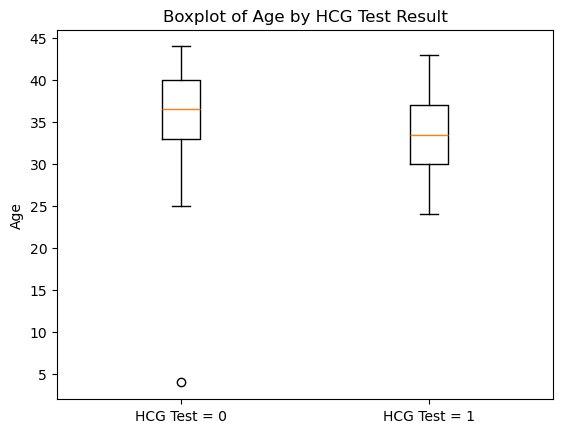

In [89]:
boxplot_variable_by_group('HCG Test', 'Age')

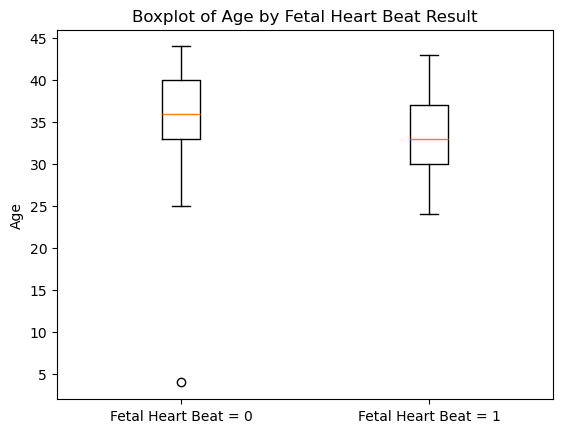

In [90]:
boxplot_variable_by_group('Fetal Heart Beat', 'Age')

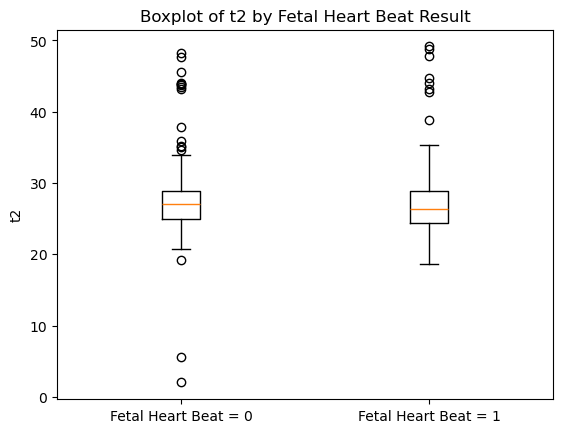

In [91]:
boxplot_variable_by_group('Fetal Heart Beat','t2')

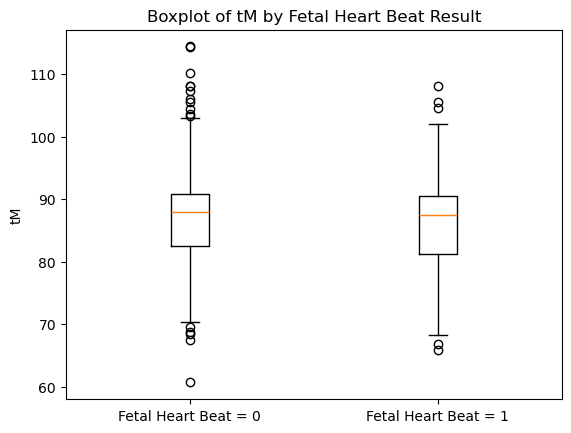

In [92]:
boxplot_variable_by_group('Fetal Heart Beat','tM')

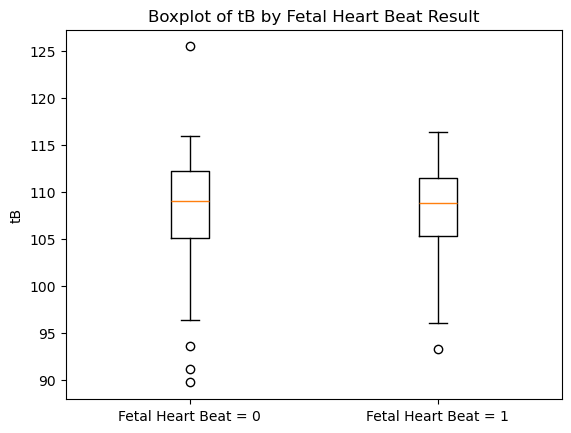

In [93]:
boxplot_variable_by_group('Fetal Heart Beat','tB')

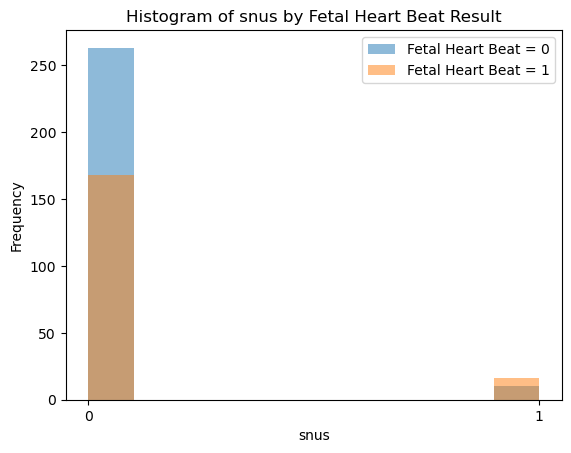

In [94]:
histogram_variable_by_group('Fetal Heart Beat', 'snus')

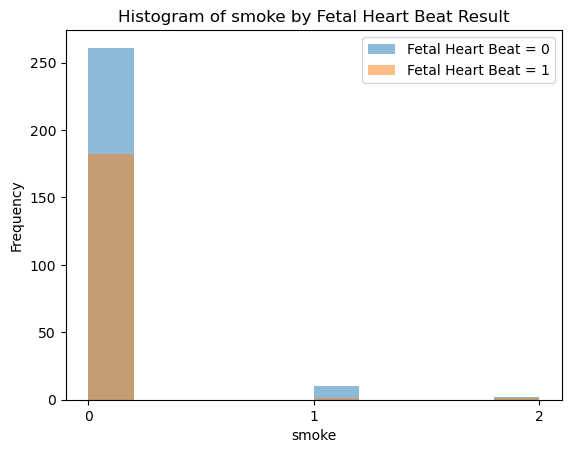

In [95]:
histogram_variable_by_group('Fetal Heart Beat', 'smoke')

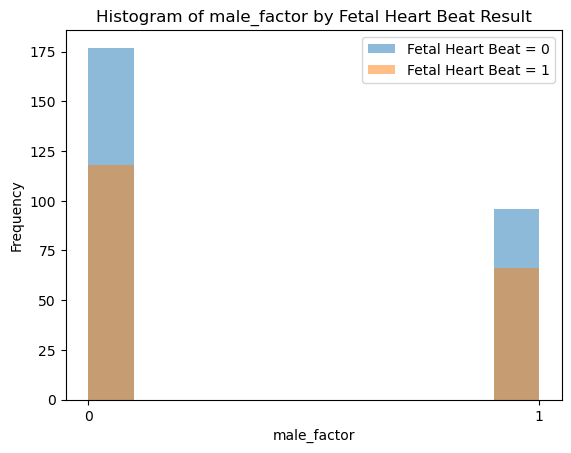

In [96]:
histogram_variable_by_group('Fetal Heart Beat', 'male_factor')

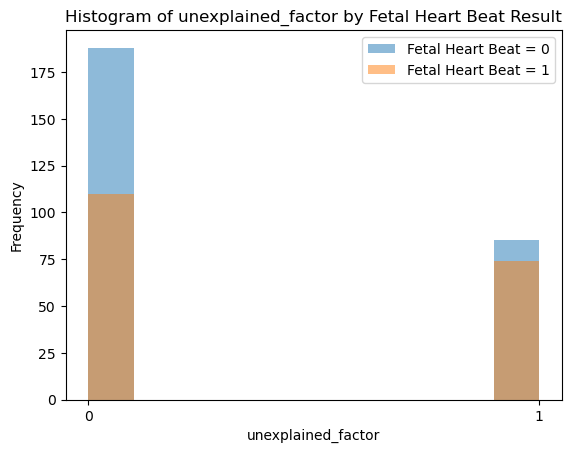

In [97]:
histogram_variable_by_group('Fetal Heart Beat', 'unexplained_factor')

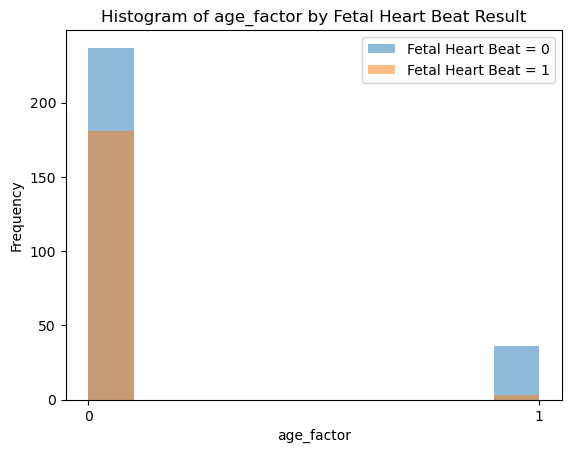

In [98]:
histogram_variable_by_group('Fetal Heart Beat', 'age_factor')

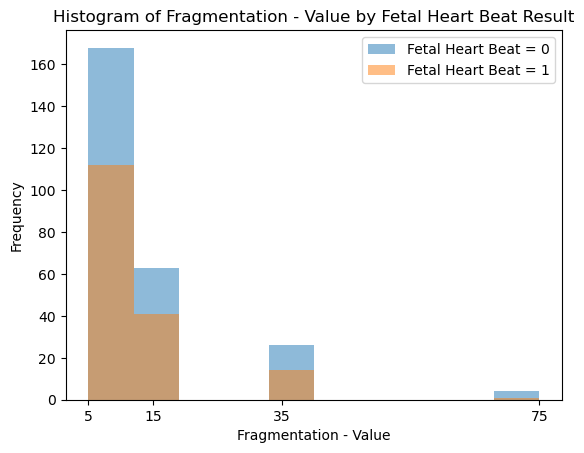

In [99]:
histogram_variable_by_group('Fetal Heart Beat', 'Fragmentation - Value')

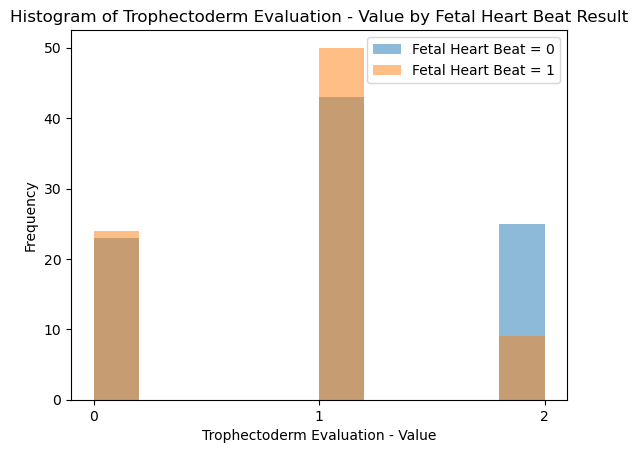

In [100]:
histogram_variable_by_group('Fetal Heart Beat', 'Trophectoderm Evaluation - Value')

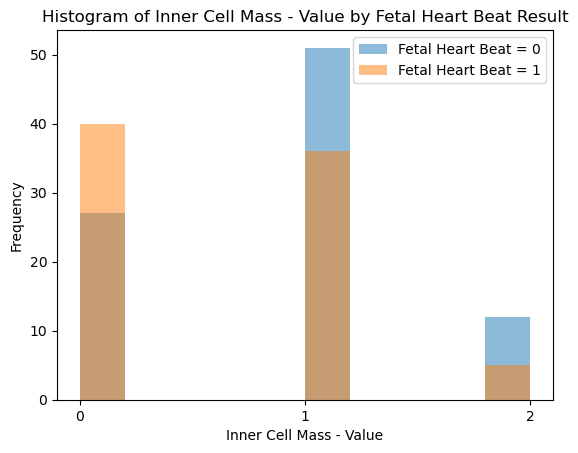

In [101]:
histogram_variable_by_group('Fetal Heart Beat', 'Inner Cell Mass - Value')

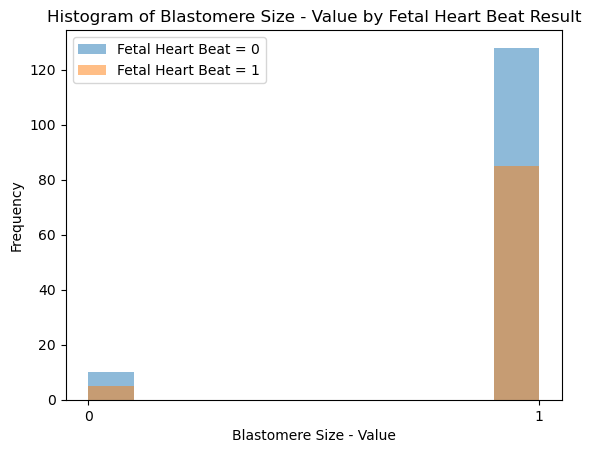

In [102]:
histogram_variable_by_group('Fetal Heart Beat', 'Blastomere Size - Value')

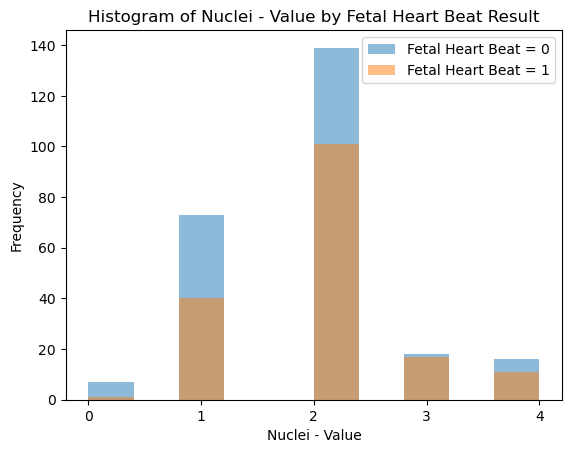

In [103]:
histogram_variable_by_group('Fetal Heart Beat', 'Nuclei - Value')

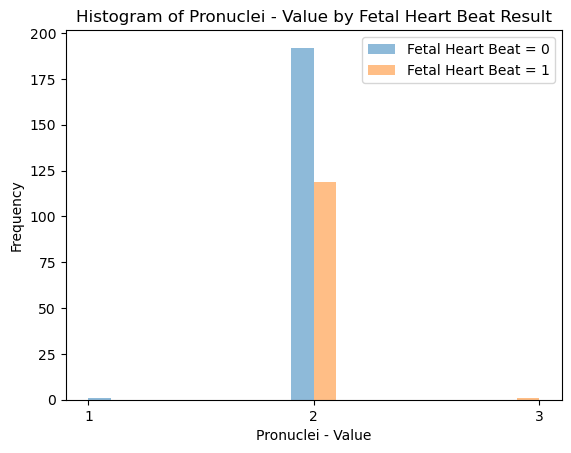

In [104]:
histogram_variable_by_group('Fetal Heart Beat', 'Pronuclei - Value')

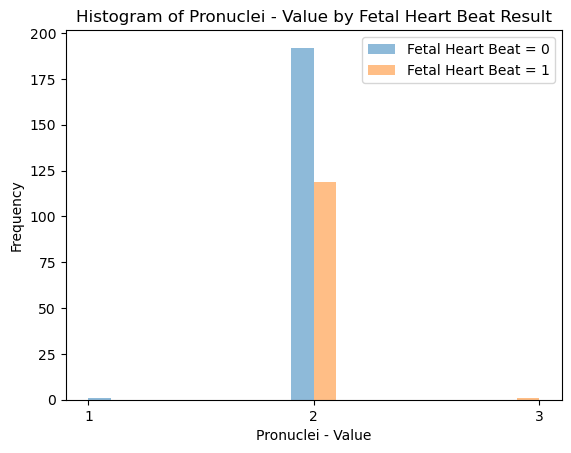

In [105]:
histogram_variable_by_group('Fetal Heart Beat', 'Pronuclei - Value')

### cleaning

In [106]:
for row in df.itertuples():
    if pd.isna(row._asdict()['t2']):
        print(row._asdict())
        df = df.drop(index=row.Index, inplace=False)
df = df.reset_index(drop=True)

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 37 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HCG Test                          460 non-null    float64
 1   number of oocytes                 455 non-null    object 
 2   IVF/ICSI                          456 non-null    object 
 3   Age                               456 non-null    float64
 4   Age_mann                          456 non-null    float64
 5   smoke                             460 non-null    float64
 6   snus                              460 non-null    float64
 7   Fetal Heart Beat                  457 non-null    object 
 8   ID                                460 non-null    object 
 9   Start Time                        460 non-null    float64
 10  Well                              460 non-null    int64  
 11  t2                                460 non-null    float64
 12  t3      

In [108]:
df['Fragmentation - Value'] = df['Fragmentation - Value'].fillna(0)

In [109]:
df

,HCG Test,number of oocytes,IVF/ICSI,Age,Age_mann,smoke,snus,Fetal Heart Beat,ID,Start Time,...,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,4,ivf,34.0,29.0,0.0,0.0,0,D2016.05.05_S0546_I427,42495.40129,...,2.0,NaN,NaN,0,0,0,0,0,0,1
1,1.0,8,ivf,34.0,41.0,0.0,0.0,0,D2016.05.14_S0631_I426,42504.40882,...,2.0,NaN,NaN,0,0,0,0,0,0,1
2,0.0,6,ivf,33.0,34.0,0.0,0.0,0,D2016.05.20_S0552_I427,42510.48947,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,11,icsi,33.0,35.0,0.0,0.0,0,D2016.05.25_S0554_I427,42515.58159,...,2.0,NaN,NaN,0,0,0,1,0,0,0
4,1.0,16,ivf,29.0,30.0,0.0,0.0,1,D2016.05.28_S0640_I426,42518.39973,...,2.0,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,3,icsi,41.0,38.0,0.0,0.0,0,D2019.05.16_S01297_I0427_D,43601.55038,...,2.0,NaN,NaN,0,0,0,1,0,0,0
456,1.0,3,ivf,38.0,38.0,0.0,0.0,1,D2019.05.17_S01299_I0427_D,43602.30562,...,NaN,NaN,NaN,0,0,0,0,0,0,1
457,1.0,9,icsi,35.0,36.0,0.0,0.0,0,D2019.05.16_S01396_I0426_D,43601.63385,...,2.0,NaN,NaN,0,0,0,1,0,0,0
458,0.0,4,icsi,39.0,37.0,0.0,0.0,0,D2019.05.15_S01392_I0426_D,43600.58583,...,2.0,NaN,NaN,0,0,0,1,0,0,0


In [110]:
df = df.drop(columns=['tSB', 'tB', 'Blastomere Size - Value', 'Multi Nucleation - Value', 'Nuclei - Value', 
                      'Pronuclei - Value', 'Inner Cell Mass - Value', 'Trophectoderm Evaluation - Value', 'tSC'])
df.reset_index(inplace=True)

In [111]:
for index,row in df.iterrows():
    if row.isna().sum() > 5:
        print(row)
df.reset_index(inplace=True)

index                                        16
HCG Test                                    0.0
number of oocytes                            12
IVF/ICSI                                    ivf
Age                                        38.0
Age_mann                                   39.0
smoke                                       0.0
snus                                        0.0
Fetal Heart Beat                              0
ID                       D2016.09.03_S0684_I426
Start Time                          42616.45946
Well                                          5
t2                                    24.471947
t3                                          NaN
t4                                          NaN
t5                                          NaN
t6                                          NaN
t7                                          NaN
t8                                          NaN
t9+                                    67.27478
tM                                    78

In [112]:
target_columns = df.loc[:, 't2':'tM']

filled_chunk = (target_columns.interpolate(axis=1)
                              .bfill(axis=1)
                              .ffill(axis=1)
                              .infer_objects(copy=False))

df.loc[:, 't2':'tM'] = filled_chunk

In [113]:
df.isnull().sum()

level_0                  0
index                    0
HCG Test                 0
number of oocytes        5
IVF/ICSI                 4
Age                      4
Age_mann                 4
smoke                    0
snus                     0
Fetal Heart Beat         3
ID                       0
Start Time               0
Well                     0
t2                       0
t3                       0
t4                       0
t5                       0
t6                       0
t7                       0
t8                       0
t9+                      0
tM                       0
Fragmentation - Value    0
ovulatory_factor         0
tubal_factor             0
endometriosis_factor     0
male_factor              0
age_factor               0
uterine_factor           0
unexplained_factor       0
dtype: int64

In [114]:
def fill_mean(df, column):
    mean_value = df[column].mean()
    if str(df[column].dtype).startswith('Int') or str(df[column].dtype).startswith('int'):
        mean_value = round(mean_value)
    df[column] = df[column].fillna(mean_value)
    return df

In [115]:
df['cc2'] = df['t4'] - df['t2']
df['cc3'] = df['t6'] - df['t3']
df['s2']  = df['t5'] - df['t3']

In [116]:
df.drop(columns=['index', 'level_0'], inplace=True)

In [117]:
excel = "/data/mvillota/EmbryoDev/Datasets/Processed/Oslo_viability/all_patient_morphk.csv"
df_new = pd.read_csv(excel)
df_new = df_new[['ID', 'Well', 'IVF/ICSI', 'number of oocytes']]

In [118]:
df.columns

Index(['HCG Test', 'number of oocytes', 'IVF/ICSI', 'Age', 'Age_mann', 'smoke',
       'snus', 'Fetal Heart Beat', 'ID', 'Start Time', 'Well', 't2', 't3',
       't4', 't5', 't6', 't7', 't8', 't9+', 'tM', 'Fragmentation - Value',
       'ovulatory_factor', 'tubal_factor', 'endometriosis_factor',
       'male_factor', 'age_factor', 'uterine_factor', 'unexplained_factor',
       'cc2', 'cc3', 's2'],
      dtype='object')

In [119]:
df = df.drop(columns=['Start Time', 'IVF/ICSI', 'number of oocytes'])

In [120]:
df_merged = pd.merge(df, df_new, on=['ID', 'Well'], how='inner')

In [121]:
df_merged = df_merged.drop(columns=['ID', 'Well'])

In [122]:
#save the cleaned dataframe to a new csv file
output_path = "tabular_data.csv"
df.to_csv(output_path, index=False) 

## Machine learning

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# Importing the expanded model suite
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from tabpfn import TabPFNClassifier

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split

In [6]:
df = pd.read_csv("tabular_data.csv")

In [7]:
df.drop(columns=['ID', 'Well'], inplace=True)
df.dropna(subset=['Fetal Heart Beat'], inplace=True)

In [8]:
df.columns

Index(['HCG Test', 'Age', 'Age_mann', 'smoke', 'snus', 'Fetal Heart Beat',
       't2', 't3', 't4', 't5', 't6', 't7', 't8', 't9+', 'tM',
       'Fragmentation - Value', 'ovulatory_factor', 'tubal_factor',
       'endometriosis_factor', 'male_factor', 'age_factor', 'uterine_factor',
       'unexplained_factor', 'cc2', 'cc3', 's2'],
      dtype='object')

In [9]:
def fill_mean(df, column):
    mean_value = df[column].mean()
    if str(df[column].dtype).startswith('Int') or str(df[column].dtype).startswith('int'):
        mean_value = round(mean_value)
    df[column] = df[column].fillna(mean_value)
    return df

In [10]:
df =fill_mean(df, 'Age')
df =fill_mean(df, 'Age_mann')

In [11]:
X = df.drop(columns=['Fetal Heart Beat', 'HCG Test'])
y = df['Fetal Heart Beat']

In [12]:
# Split the dataset: 80% for training and 20% for testing the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # 20% for testing (94 patients)
    random_state=42,    # Seed to ensure the experiment is reproducible
    stratify=y          # Maintains the same proportion of hCG successes/failures in both sets
)

print(f"Patients for training: {X_train.shape[0]}")
print(f"Patients for testing: {X_test.shape[0]}")

Patients for training: 365
Patients for testing: 92


In [161]:
y_train = list(y_train)
y_test = list(y_test)

In [13]:
classifiers = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__penalty': ['l2']
        }
    },
    'DecisionTree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'classifier__criterion': ['gini', 'entropy'],
            'classifier__max_depth': [None, 4, 6, 8, 12],
            'classifier__min_samples_split': [2, 5, 10]
        }
    },
    'SVC': {
        'model': SVC(probability=True, random_state=42), # probability=True is needed for ROC-AUC / prediction thresholds
        'params': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__kernel': ['linear', 'rbf'],
            'classifier__gamma': ['scale', 'auto']
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'classifier__n_neighbors': [3, 5, 7, 11, 15],
            'classifier__weights': ['uniform', 'distance'],
            'classifier__metric': ['euclidean', 'manhattan']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__min_samples_split': [2, 5]
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__criterion': ['gini', 'entropy']
        }
    },
    'GradientBoosting': {
        'model': HistGradientBoostingClassifier(random_state=42),
        'params': {
            'classifier__learning_rate': [0.01, 0.05, 0.1],
            'classifier__max_iter': [100, 150],
            'classifier__max_depth': [3, 5, 7]
        }
    },
    # 'TabPFN': {
    #     'model': TabPFNClassifier(ignore_pretraining_limits=True,device='cpu'),
    #     'params': {}
    # }
}

In [14]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {}
best_score = 0
best_pipeline = None
best_model_name = ""

print("--- Starting Extensive Cross-Validation Grid Search ---")
for name, config in classifiers.items():
    # Constructing the structural pipeline for each model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', config['model'])
    ])
    
    # Running GridSearch optimizing for ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    print(f"🔹 {name:<20} -> Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    models[name] = grid_search
    
    # Track down the absolute king of performance
    if grid_search.best_score_ > best_score:
        best_score = grid_search.best_score_
        best_pipeline = grid_search.best_estimator_
        best_model_name = name

--- Starting Extensive Cross-Validation Grid Search ---


🔹 LogisticRegression   -> Best CV ROC-AUC: 0.6071
🔹 DecisionTree         -> Best CV ROC-AUC: 0.5548
🔹 SVC                  -> Best CV ROC-AUC: 0.5917
🔹 KNN                  -> Best CV ROC-AUC: 0.5705
🔹 RandomForest         -> Best CV ROC-AUC: 0.6078
🔹 ExtraTrees           -> Best CV ROC-AUC: 0.6133
🔹 GradientBoosting     -> Best CV ROC-AUC: 0.6061


In [15]:
print(f"\n WINNER MODEL: {best_model_name} (CV ROC-AUC: {best_score:.4f})")
print(best_pipeline)


 WINNER MODEL: ExtraTrees (CV ROC-AUC: 0.6133)
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 ExtraTreesClassifier(max_depth=5, n_estimators=200,
                                      random_state=42))])


In [165]:
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.7263

                 precision    recall  f1-score   support

FHB Failure (0)       0.69      0.93      0.79        55
FHB Success (1)       0.78      0.38      0.51        37

       accuracy                           0.71        92
      macro avg       0.73      0.65      0.65        92
   weighted avg       0.72      0.71      0.68        92



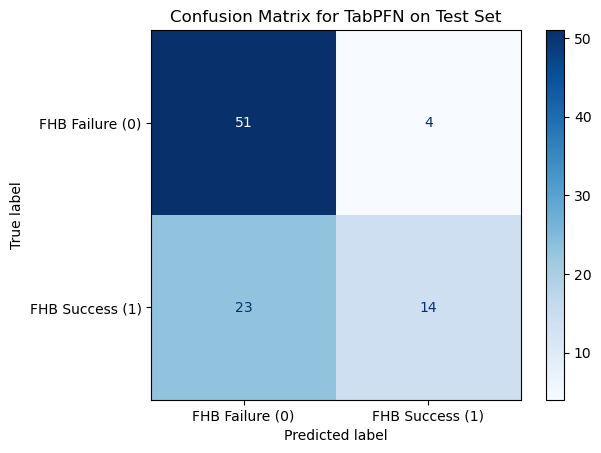

In [166]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

In [16]:
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
for model in models:
    best_pipeline = models[model].best_estimator_
    y_pred = best_pipeline.predict(X_test)
    y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]
    print(f"{model}: {roc_auc_score(y_test, y_pred_proba):.4f} ")


--- Final Test Set Evaluation (Unseen Patients) ---
LogisticRegression: 0.7351 
DecisionTree: 0.5663 
SVC: 0.6929 
KNN: 0.6140 
RandomForest: 0.6376 
ExtraTrees: 0.6796 
GradientBoosting: 0.6447 


In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score
# compute all the metrics
print('accuracy:', best_pipeline.score(X_test, y_test))
print('precision:', precision_score(y_test, best_pipeline.predict(X_test)))
print('recall:', recall_score(y_test, best_pipeline.predict(X_test)))
print('f1:', f1_score(y_test, best_pipeline.predict(X_test)))

accuracy: 0.5978260869565217
precision: 0.5
recall: 0.3783783783783784
f1: 0.4307692307692308


/home/mvillota/anaconda3/envs/torch_cuda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 92/92 [00:09<00:00,  9.43it/s]


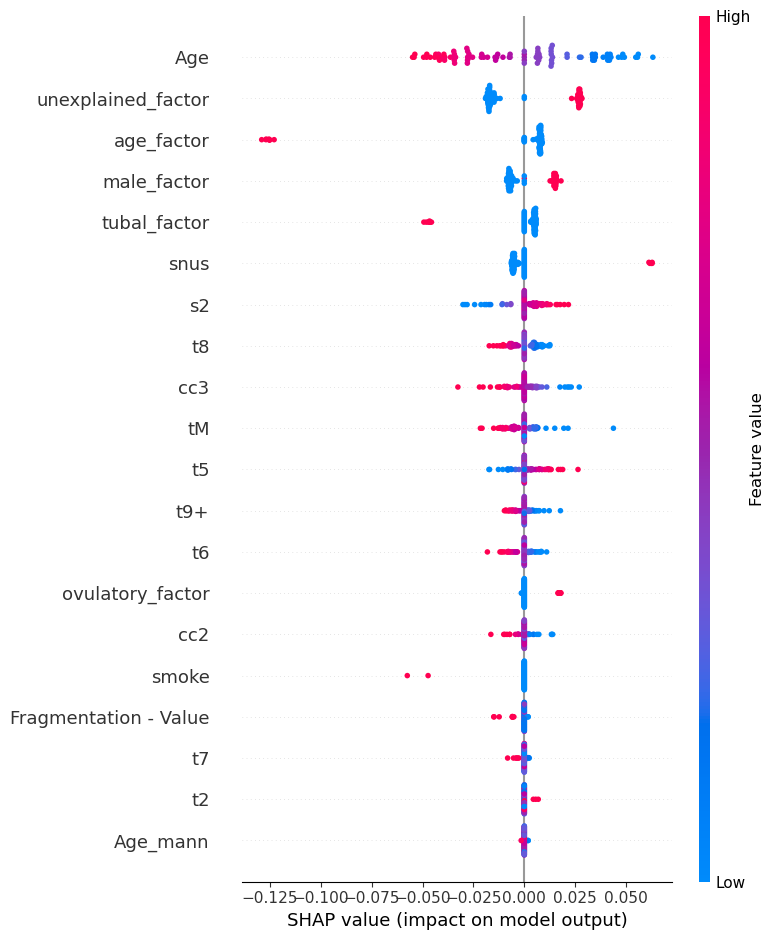

In [18]:
import shap
import numpy as np
import pandas as pd


# 1. Extraer el mejor pipeline (LogisticRegression) generado por tu GridSearchCV
best_pipeline = models['LogisticRegression'].best_estimator_

# 2. Definir la función wrapper para SHAP
# Garantiza que el Pipeline reciba siempre un DataFrame con nombres de columnas
def predict_proba_pipeline(x):
    if isinstance(x, np.ndarray):
        x = pd.DataFrame(x, columns=X_train.columns)
    return best_pipeline.predict_proba(x)

# 3. Muestrear datos de fondo (Background Data) desde X_train
# Usar entre 50 y 100 muestras para equilibrar precisión y velocidad
background_data = shap.sample(X_train, 50, random_state=42)

# 4. Inicializar KernelExplainer enviando el wrapper y la muestra sin escalar
explainer = shap.KernelExplainer(predict_proba_pipeline, background_data)

# 5. Calcular valores SHAP para el conjunto de prueba (X_test)
shap_values = explainer.shap_values(X_test)

# 6. Visualización de la importancia de características
# Para clasificación binaria (clase 1 - FHB Success):
if isinstance(shap_values, list):
    # En versiones de SHAP donde devuelve una lista por clase [clase_0, clase_1]
    shap.summary_plot(shap_values[1], X_test)
else:
    # En versiones más recientes donde la salida es un array 3D (muestras, features, clases)
    shap.summary_plot(shap_values[:, :, 1], X_test)

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Extraer el mejor pipeline (LogisticRegression) generado por tu GridSearchCV
best_pipeline = models['LogisticRegression'].best_estimator_

# 2. Definir la función wrapper para SHAP
def predict_proba_pipeline(x):
    if isinstance(x, np.ndarray):
        x = pd.DataFrame(x, columns=X_train.columns)
    return best_pipeline.predict_proba(x)

# 3. Muestrear datos de fondo (Background Data) desde X_train
background_data = shap.sample(X_train, 50, random_state=42)

# 4. Inicializar KernelExplainer enviando el wrapper y la muestra sin escalar
explainer = shap.KernelExplainer(predict_proba_pipeline, background_data)

# 5. Calcular valores SHAP para el conjunto de prueba (X_test)
shap_values = explainer.shap_values(X_test)

In [ ]:
X_test_formatted = X_test.copy()
X_test_formatted.columns = [
    col.replace("_", " ").upper() if col.lower() != "zp_r" else "ZP r"
    for col in X_test.columns
]
X_test_formatted.columns = [col.replace("AGE MANN", "AGE MAN") for col in X_test_formatted.columns]
X_test_formatted.columns = [col.replace("FRAGMENTATION - VALUE", "FRAGMENTATION IDX") for col in X_test_formatted.columns]

In [31]:
X_test_formatted.columns = [col.replace("AGE", "AGE WOMAN") for col in X_test_formatted.columns]

In [33]:
X_test_formatted.columns = [col.replace("T9+", "T9") for col in X_test_formatted.columns]

In [34]:
X_test_formatted.columns

Index(['AGE WOMAN', 'AGE WOMAN MAN', 'SMOKE', 'SNUS', 'T2', 'T3', 'T4', 'T5',
       'T6', 'T7', 'T8', 'T9', 'TM', 'FRAGMENTATION IDX', 'OVULATORY FACTOR',
       'TUBAL FACTOR', 'ENDOMETRIOSIS FACTOR', 'MALE FACTOR',
       'AGE WOMAN FACTOR', 'UTERINE FACTOR', 'UNEXPLAINED FACTOR', 'CC2',
       'CC3', 'S2'],
      dtype='object')

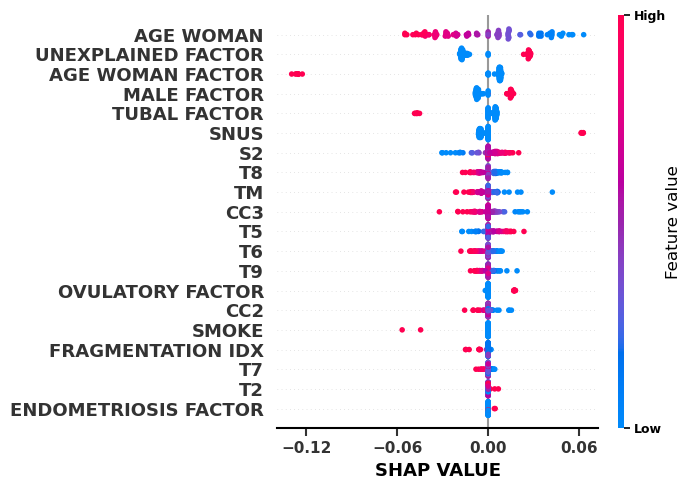

In [35]:
# 6. Configuración global de estilos estilo GraphPad Prism
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.5,
    "lines.linewidth": 1.5,
})

fig, ax = plt.subplots(figsize=(7, 5))

# Generar el beeswarm plot en el axis personalizado de Matplotlib
shap.summary_plot(
    vals_class1,
    X_test_formatted,
    plot_type="dot",
    show=False,
    color_bar=True,
    plot_size=None
)

# 7. Aplicar estética estricta GraphPad Prism sobre el gráfico generado por SHAP
ax = plt.gca()

# Quitar espinas superior e derecha
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Engrosar espinas izquierda e inferior
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

# Ticks más largos y gruesos hacia afuera
ax.tick_params(axis="both", which="both", direction="out", length=6, width=1.5)

# Limitar eje X a 4-5 ticks máximos
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

# Personalizar etiquetas de ejes
ax.set_xlabel("SHAP VALUE", fontweight="bold")

# Forzar negrita en todas las etiquetas de los ticks (variables y valores de ticks)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

# Estilar la barra de color (Colorbar) estilo GraphPad si existe
fig = plt.gcf()
for cax in fig.get_axes():
    if cax != ax:
        cax.spines["top"].set_visible(False)
        cax.spines["right"].set_visible(False)
        cax.spines["left"].set_visible(False)
        cax.spines["bottom"].set_visible(False)
        cax.tick_params(labelsize=9, length=4, width=1.2)
        for label in cax.get_yticklabels():
            label.set_fontweight("bold")

plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300, bbox_inches="tight")
plt.show()

100%|██████████| 92/92 [00:07<00:00, 12.29it/s]


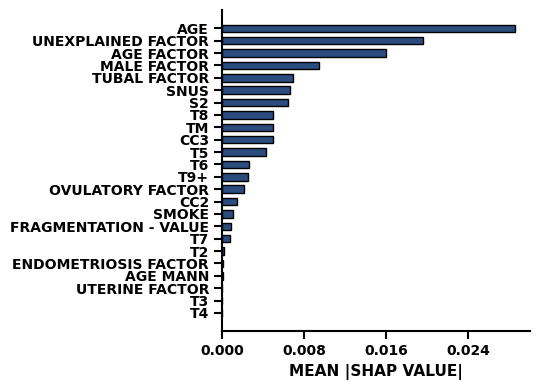

In [ ]:


# Extraer array para la Clase 1 (FHB Success)
if isinstance(shap_values, list):
    vals_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    vals_class1 = shap_values[:, :, 1]
else:
    vals_class1 = shap_values

# 6. Formatear y calcular importancias globales
mean_abs_shap = np.abs(vals_class1).mean(axis=0)
feature_names = [col.replace("_", " ").upper() for col in X_train.columns]

df_shap = pd.Series(mean_abs_shap, index=feature_names).sort_values(ascending=True)

# 7. Configuración de Estilo GraphPad Prism
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.5,
})

BAR_COLOR = "#2B4C7E"  # Slate Navy Prism Style

fig, ax = plt.subplots(figsize=(5.5, 4.0))

# Crear barras horizontales
y_pos = np.arange(len(df_shap))
ax.barh(y_pos, df_shap.values, color=BAR_COLOR, height=0.6, edgecolor="black", linewidth=1.0)

# Configurar ejes y etiquetas
ax.set_yticks(y_pos)
ax.set_yticklabels(df_shap.index, fontweight="bold")
ax.set_xlabel("MEAN |SHAP VALUE|", fontweight="bold")

# Limitar a 4-5 ticks máximos en el eje X
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

# Estilo de espinas y ticks estilo GraphPad Prism
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="both", direction="out", length=6, width=1.5)

# Forzar negrita en todas las etiquetas de los ticks
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

fig.tight_layout()
plt.show()

In [ ]:
# 1. Extraer el mejor pipeline (LogisticRegression) generado por tu GridSearchCV
best_pipeline = models['TabPFN'].best_estimator_

# 2. Definir la función wrapper para SHAP
# Garantiza que el Pipeline reciba siempre un DataFrame con nombres de columnas
def predict_proba_pipeline(x):
    if isinstance(x, np.ndarray):
        x = pd.DataFrame(x, columns=X_train.columns)
    return best_pipeline.predict_proba(x)

# 3. Muestrear datos de fondo (Background Data) desde X_train
# Usar entre 50 y 100 muestras para equilibrar precisión y velocidad
background_data = shap.sample(X_train, 50, random_state=42)

# 4. Inicializar KernelExplainer enviando el wrapper y la muestra sin escalar
explainer = shap.KernelExplainer(predict_proba_pipeline, background_data)

# 5. Calcular valores SHAP para el conjunto de prueba (X_test)
shap_values = explainer.shap_values(X_test)

# 6. Visualización de la importancia de características
# Para clasificación binaria (clase 1 - FHB Success):
if isinstance(shap_values, list):
    # En versiones de SHAP donde devuelve una lista por clase [clase_0, clase_1]
    shap.summary_plot(shap_values[1], X_test)
else:
    # En versiones más recientes donde la salida es un array 3D (muestras, features, clases)
    shap.summary_plot(shap_values[:, :, 1], X_test)

  0%|          | 0/92 [00:00<?, ?it/s]

### TabPFN

In [78]:
#extract time prediction
import time
best_pipeline = models['TabPFN'].best_estimator_
start_time = time.time()
y_pred = best_pipeline.predict(X_test)
end_time = time.time()
print(f"Time taken: {end_time - start_time:.2f} seconds")


Time taken: 4.38 seconds


In [79]:
len(y_pred)

92

In [19]:
best_pipeline = models['TabPFN'].best_estimator_
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.7319

                 precision    recall  f1-score   support

FHB Failure (0)       0.68      0.95      0.79        55
FHB Success (1)       0.80      0.32      0.46        37

       accuracy                           0.70        92
      macro avg       0.74      0.63      0.62        92
   weighted avg       0.73      0.70      0.66        92



In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score
# compute all the metrics
print('accuracy:', best_pipeline.score(X_test, y_test))
print('precision:', precision_score(y_test, best_pipeline.predict(X_test)))
print('recall:', recall_score(y_test, best_pipeline.predict(X_test)))
print('f1:', f1_score(y_test, best_pipeline.predict(X_test)))

accuracy: 0.6956521739130435
precision: 0.8
recall: 0.32432432432432434
f1: 0.46153846153846156


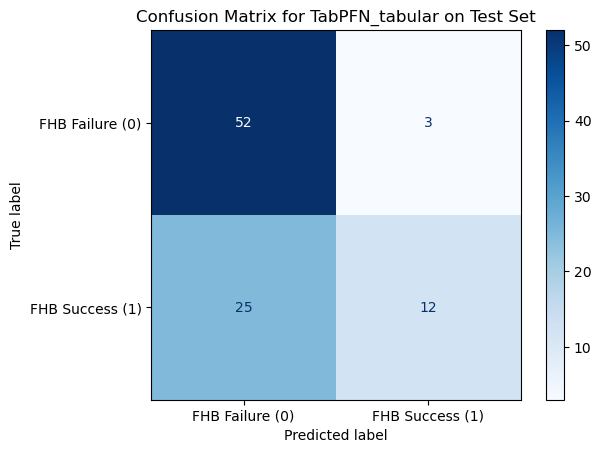

In [21]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
best_model_name = 'TabPFN_tabular'
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.savefig(f'confusion_matrix_{best_model_name}.png')
plt.show()

In [22]:
X_train

,Age,Age_mann,smoke,snus,t2,t3,t4,t5,t6,t7,...,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor,cc2,cc3,s2
182,42.0,43.0,0.0,0.0,25.443362,40.153211,40.153211,54.278741,54.278741,54.278741,...,0,0,0,0,1,0,0,14.709848,14.125530,14.125530
202,32.0,35.0,0.0,0.0,26.255086,33.376355,35.010573,48.285616,48.752288,51.557696,...,1,0,0,0,0,0,0,8.755487,15.375933,14.909261
348,37.0,39.0,0.0,0.0,32.277639,39.399695,40.099705,54.017856,55.535828,62.074728,...,0,0,0,1,0,0,0,7.822066,16.136133,14.618161
137,31.0,29.0,0.0,0.0,22.838983,33.929801,37.315618,46.654241,49.105866,52.841415,...,1,1,0,0,0,0,0,14.476635,15.176065,12.724439
48,36.0,36.0,0.0,0.0,28.970359,39.945683,42.980922,52.904736,55.940126,56.056819,...,0,1,0,0,0,0,0,14.010564,15.994444,12.959053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,40.0,47.0,0.0,0.0,22.234053,33.679657,33.679657,42.323059,43.143856,47.133726,...,0,0,0,1,0,0,0,11.445604,9.464199,8.643402
217,33.0,35.0,0.0,0.0,44.698887,44.698887,44.698887,46.334523,46.918307,47.969089,...,0,0,0,0,0,0,1,0.000000,2.219421,1.635637
453,40.0,51.0,0.0,0.0,27.046334,37.300439,37.300439,49.604728,52.105671,53.106218,...,0,1,0,1,0,0,0,10.254105,14.805232,12.304289
404,41.0,40.0,0.0,0.0,24.152001,40.263224,40.263224,47.735006,50.069839,52.871167,...,0,0,0,0,1,0,0,16.111223,9.806615,7.471783


/home/mvillota/anaconda3/envs/torch_cuda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 92/92 [13:25<00:00,  8.75s/it]


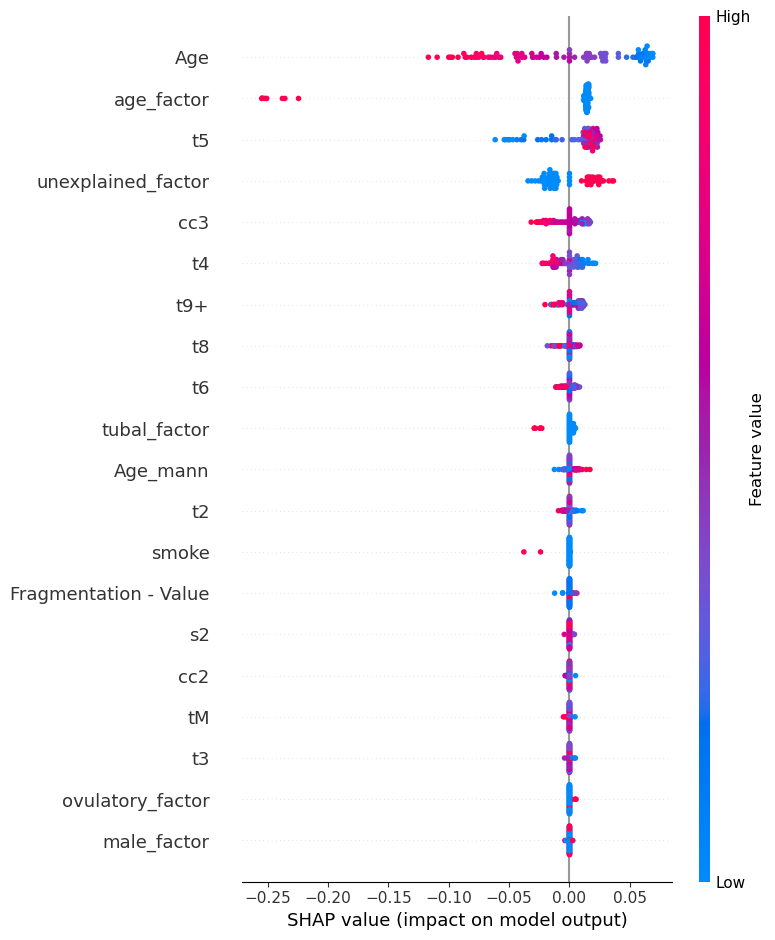

In [23]:
import shap
import numpy as np
import pandas as pd

# 1. Extraer el mejor pipeline (TabPFN) generado por tu GridSearchCV
best_pipeline = models['TabPFN'].best_estimator_

# 2. Definir la función wrapper para SHAP
# Garantiza que el Pipeline reciba siempre un DataFrame con nombres de columnas
def predict_proba_pipeline(x):
    if isinstance(x, np.ndarray):
        x = pd.DataFrame(x, columns=X_train.columns)
    return best_pipeline.predict_proba(x)

# 3. Muestrear datos de fondo (Background Data) desde X_train
# Usar entre 50 y 100 muestras para equilibrar precisión y velocidad
background_data = shap.sample(X_train, 50, random_state=42)

# 4. Inicializar KernelExplainer enviando el wrapper y la muestra sin escalar
explainer = shap.KernelExplainer(predict_proba_pipeline, background_data)

# 5. Calcular valores SHAP para el conjunto de prueba (X_test)
shap_values = explainer.shap_values(X_test)

# 6. Visualización de la importancia de características
# Para clasificación binaria (clase 1 - FHB Success):
if isinstance(shap_values, list):
    # En versiones de SHAP donde devuelve una lista por clase [clase_0, clase_1]
    shap.summary_plot(shap_values[1], X_test)
else:
    # En versiones más recientes donde la salida es un array 3D (muestras, features, clases)
    shap.summary_plot(shap_values[:, :, 1], X_test)

### LogisticRegression

In [24]:
best_pipeline = models['LogisticRegression'].best_estimator_
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.7199

                 precision    recall  f1-score   support

FHB Failure (0)       0.62      0.96      0.76        55
FHB Success (1)       0.71      0.14      0.23        37

       accuracy                           0.63        92
      macro avg       0.67      0.55      0.49        92
   weighted avg       0.66      0.63      0.54        92



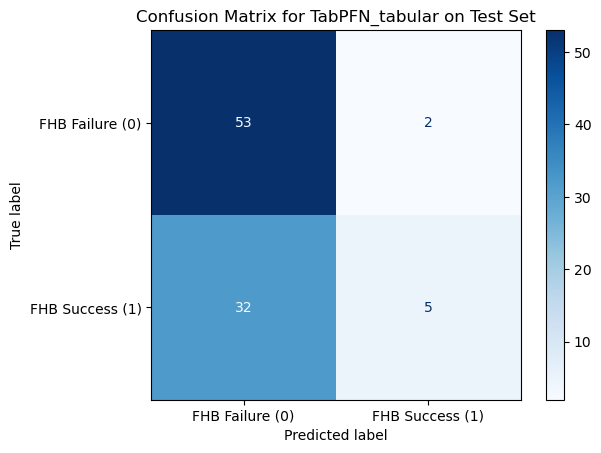

In [25]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

In [26]:
weights = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_pipeline.named_steps['classifier'].coef_[0] if hasattr(best_pipeline.named_steps['classifier'], 'coef_') else None
})

In [27]:
weights = weights.sort_values(by='Coefficient', key=lambda x: abs(x), ascending=False).reset_index(drop=True)


In [28]:
print("\n--- Feature Importance / Coefficients ---")
if weights['Coefficient'].isnull().all():
    print("The selected model does not provide coefficients (e.g., tree-based models).")
else:
    print(weights)


--- Feature Importance / Coefficients ---
                  Feature  Coefficient
0              age_factor    -0.179468
1                     Age    -0.139644
2      unexplained_factor     0.089790
3            tubal_factor    -0.065464
4                   smoke    -0.055252
5                      s2     0.047248
6             male_factor     0.045831
7                      tM    -0.040654
8                     cc3    -0.039155
9                      t5     0.036445
10                     t8    -0.026552
11                     t6    -0.026099
12       ovulatory_factor     0.024239
13                    t9+    -0.023724
14                    cc2    -0.021496
15                     t4    -0.011144
16                     t7    -0.010414
17  Fragmentation - Value    -0.009512
18               Age_mann    -0.006545
19   endometriosis_factor     0.006005
20                     t2     0.005707
21                     t3     0.004219
22                   snus     0.000000
23         uterine_fa

In [123]:
weights.to_csv('feature_importance_coefficients.csv', index=False)

Text(0, 0.5, 'Coefficient Value')

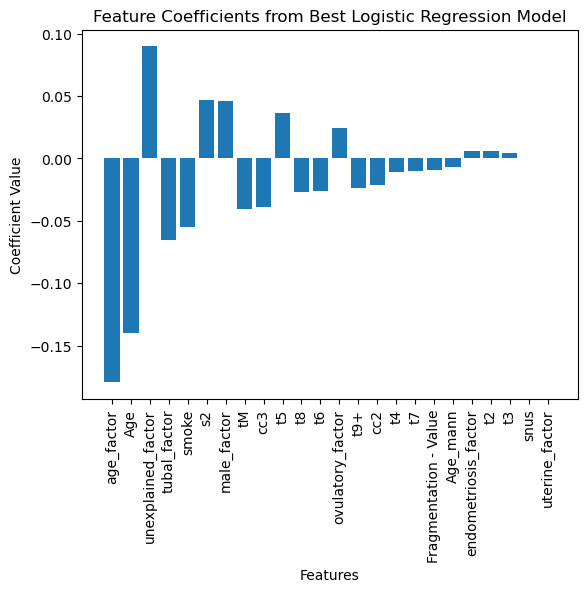

In [122]:
plt.bar(weights['Feature'], weights['Coefficient'])
plt.xticks(rotation=90)
plt.title('Feature Coefficients from Best Logistic Regression Model')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')

### Ensemble

In [ ]:
from sklearn.ensemble import VotingClassifier

eclf = VotingClassifier(
    estimators=[(m, models[m].best_estimator_) for m in ['LogisticRegression', 'TabPFN']],
    voting='soft'
)

eclf.fit(X_train, y_train)
y_pred = eclf.predict(X_test)
y_proba = eclf.predict_proba(X_test)[:, 1]

In [ ]:
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))

Test Set ROC-AUC Score: 0.7405

                 precision    recall  f1-score   support

FHB Failure (0)       0.67      0.98      0.79        55
FHB Success (1)       0.91      0.27      0.42        37

       accuracy                           0.70        92
      macro avg       0.79      0.63      0.61        92
   weighted avg       0.76      0.70      0.64        92



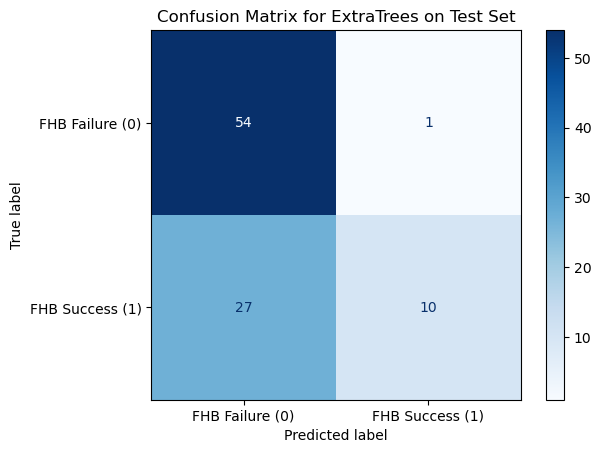

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

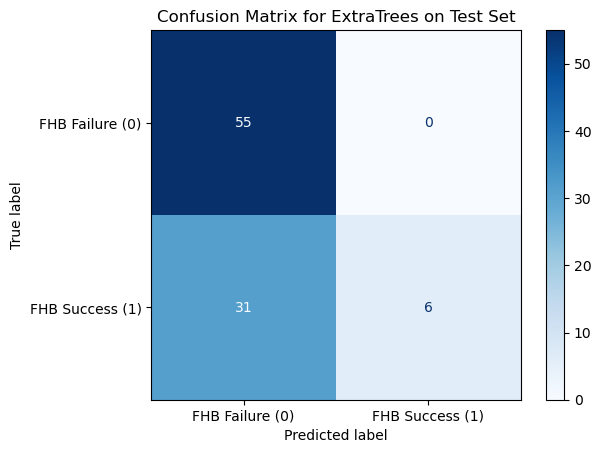

In [ ]:
eclf = VotingClassifier(
    estimators=[(m, models[m].best_estimator_) for m in ['LogisticRegression', 'TabPFN']],
    voting='hard'
)

eclf.fit(X_train, y_train)
y_pred = eclf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

### Algoritmo ASEBIR

In [ ]:
df_times = df[['t2', 'cc2', 'cc3', 's2', 'Fetal Heart Beat']].dropna()

In [ ]:
float(np.mean(df_times.loc[df_times['cc2'] <= 5, 'Fetal Heart Beat']))*100

41.66666666666667

In [ ]:
df_cc2_5 = df_times.loc[df_times['cc2'] > 5]
float(np.mean(df_cc2_5.loc[df_cc2_5['s2'] >= 5, 'Fetal Heart Beat']))*100

41.14713216957606

In [ ]:
df_s2 = df_cc2_5[df_cc2_5['s2'] < 5]
df_cc3 = df_s2[(df_s2['cc3'] > 11) & (df_s2['cc3'] < 15)]

In [ ]:
df_cc3.loc[(df_cc3['t2'] < 24) & (df_cc3['t2'] > 25), 'Fetal Heart Beat']

Series([], Name: Fetal Heart Beat, dtype: object)

In [ ]:
X = df[['t2', 'cc2', 'cc3', 's2']]
y = df['Fetal Heart Beat']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # 20% for testing (94 patients)
    random_state=42,    # Seed to ensure the experiment is reproducible
    stratify=y          # Maintains the same proportion of hCG successes/failures in both sets
)

print(f"Patients for training: {X_train.shape[0]}")
print(f"Patients for testing: {X_test.shape[0]}")
y_train = list(y_train)
y_test = list(y_test)

Patients for training: 365
Patients for testing: 92


In [ ]:
# 1. Define an extensive dictionary of models and hyperparameter grids
classifiers = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__penalty': ['l2']
        }
    },
    'DecisionTree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'classifier__criterion': ['gini', 'entropy'],
            'classifier__max_depth': [None, 4, 6, 8, 12],
            'classifier__min_samples_split': [2, 5, 10]
        }
    },
    'SVC': {
        'model': SVC(probability=True, random_state=42), # probability=True is needed for ROC-AUC / prediction thresholds
        'params': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__kernel': ['linear', 'rbf'],
            'classifier__gamma': ['scale', 'auto']
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'classifier__n_neighbors': [3, 5, 7, 11, 15],
            'classifier__weights': ['uniform', 'distance'],
            'classifier__metric': ['euclidean', 'manhattan']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__min_samples_split': [2, 5]
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__criterion': ['gini', 'entropy']
        }
    },
    'GradientBoosting': {
        'model': HistGradientBoostingClassifier(random_state=42),
        'params': {
            'classifier__learning_rate': [0.01, 0.05, 0.1],
            'classifier__max_iter': [100, 150],
            'classifier__max_depth': [3, 5, 7]
        }
    }
}

# 2. Setup Stratified 5-Fold Cross Validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_score = 0
best_pipeline = None
best_model_name = ""

print("--- Starting Extensive Cross-Validation Grid Search ---")
for name, config in classifiers.items():
    # Constructing the structural pipeline for each model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', config['model'])
    ])
    
    # Running GridSearch optimizing for ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    print(f"🔹 {name:<20} -> Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    
    # Track down the absolute king of performance
    if grid_search.best_score_ > best_score:
        best_score = grid_search.best_score_
        best_pipeline = grid_search.best_estimator_
        best_model_name = name

print(f"\n WINNER MODEL: {best_model_name} (CV ROC-AUC: {best_score:.4f})")
print(best_pipeline)

# 3. Final Evaluation on Holdout Test Set
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Implantation Failure (0)', 'Implantation Success (1)']))

--- Starting Extensive Cross-Validation Grid Search ---


🔹 LogisticRegression   -> Best CV ROC-AUC: 0.5094
🔹 DecisionTree         -> Best CV ROC-AUC: 0.5057
🔹 SVC                  -> Best CV ROC-AUC: 0.5595
🔹 KNN                  -> Best CV ROC-AUC: 0.5639
🔹 RandomForest         -> Best CV ROC-AUC: 0.5143
🔹 ExtraTrees           -> Best CV ROC-AUC: 0.5351
🔹 GradientBoosting     -> Best CV ROC-AUC: 0.5078

 WINNER MODEL: KNN (CV ROC-AUC: 0.5639)
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(metric='manhattan'))])

--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.4808

                          precision    recall  f1-score   support

Implantation Failure (0)       0.57      0.75      0.65        55
Implantation Success (1)       0.30      0.16      0.21        37

                accuracy                           0.51        92
               macro avg       0.43      0.45      0.43        92
            weighted avg       0.46      0.51      0.47        92



In [ ]:
clf = DecisionTreeClassifier(random_state=42, max_depth=10, criterion='gini')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.58      0.67      0.62        55
           1       0.36      0.27      0.31        37

    accuracy                           0.51        92
   macro avg       0.47      0.47      0.46        92
weighted avg       0.49      0.51      0.50        92



In [ ]:
# print decision tree rules
from sklearn.tree import export_text
tree_rules = export_text(clf, feature_names=list(X.columns))
print(tree_rules)

|--- cc3 <= 16.52
|   |--- t2 <= 25.44
|   |   |--- s2 <= 0.53
|   |   |   |--- class: 0
|   |   |--- s2 >  0.53
|   |   |   |--- cc2 <= 9.05
|   |   |   |   |--- cc2 <= 7.54
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- cc2 >  7.54
|   |   |   |   |   |--- class: 0
|   |   |   |--- cc2 >  9.05
|   |   |   |   |--- t2 <= 22.97
|   |   |   |   |   |--- cc2 <= 11.97
|   |   |   |   |   |   |--- cc3 <= 9.98
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- cc3 >  9.98
|   |   |   |   |   |   |   |--- t2 <= 22.73
|   |   |   |   |   |   |   |   |--- s2 <= 12.63
|   |   |   |   |   |   |   |   |   |--- cc3 <= 11.98
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |--- cc3 >  11.98
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- s2 >  12.63
|   |   |   |   |   |   |   |   |   |--- cc2 <= 11.33
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |

# Statistics Report

### Categorical variables
1. Smoking vs Implantation

    H_0: Smoking has no association with implantation success
    
    H_1: They are dependent

In [21]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from scipy.stats import fisher_exact

In [15]:
implantation = {
    'hcg testpositiv': 1,
    'pos': 1,
    'positiv': 1,
    'biokjemisk': 1,       
    'neg': 0,
    'negativ': 0,
    'negative': 0,
    'negativ (står positiv i lf uten mer informasjon, men neg. i sys.x.)': 0
}
df['HCG Test'] = df['HCG Test'].map(implantation)

In [22]:
def chi_statistics(contingency_table):
    chi2, p, dof, expected_frequencies = chi2_contingency(contingency_table)
    expected_df = pd.DataFrame(expected_frequencies, 
                           index=contingency_table.index, 
                           columns=contingency_table.columns)

    print("--- Expected Counts (If No Relationship Existed) ---")
    print(expected_df, "\n")
    print("--- Statistical Results ---")
    print(f"Chi-squared Statistic: {chi2:.4f}")
    print(f"Degrees of Freedom: {dof}")
    print(f"p-value: {p:.4e}") # Displays in scientific notation if very small

    # Evaluate p-value (Alpha = 0.05)
    alpha = 0.05
    if p < alpha:
        print(f"✅ Reject the Null Hypothesis (p < {alpha}).")
        print("There is a statistically significant association between the two variables.")
    else:
        print(f"❌ Fail to Reject the Null Hypothesis (p >= {alpha}).")
        print("There is no evidence of a significant association between the variables.")

In [23]:
def fisher_statistics(contingency_table):
    odds_ratio, p_value = fisher_exact(contingency_table)

    print("--- Statistical Results ---")
    print(f"Odds Ratio (OR): {odds_ratio:.4f}")
    print(f"p-value: {p_value:.4f}")

    print("\n--- Clinical Interpretation ---")
    alpha = 0.05
    if p_value < alpha:
        print(f"✅ Reject $H_0$ (p < {alpha}). The association is statistically significant.")
        if odds_ratio < 1:
            print("Interpretation: The exposure factor (e.g., Smoking) is associated with LOWER odds of Implantation Success.")
        elif odds_ratio > 1:
            print("Interpretation: The exposure factor is associated with HIGHER odds of Implantation Success.")
    else:
        print(f"❌ Fail to Reject $H_0$ (p >= {alpha}).")
        print("No statistically significant association was found between the two variables.")

In [24]:
def categorical_statistics(contingency_table):
    if (contingency_table < 5).any().any():
        print("⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.\n")
        fisher_statistics(contingency_table)
    else:
        chi_statistics(contingency_table)

In [25]:
def var_categorical_statistics(df, variable, group_var='HCG Test'):
    contingency_table = pd.crosstab(df[variable], df[group_var])
    print(f"--- Contingency Table for {variable} vs {group_var} ---")
    print(contingency_table, "\n")
    categorical_statistics(contingency_table)

In [26]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact

def var_categorical_statistics(df, variable, group_var='HCG Test'):
    # Eliminar NaNs para la tabla de contingencia
    clean_df = df.dropna(subset=[variable, group_var])
    contingency_table = pd.crosstab(clean_df[variable], clean_df[group_var])
    
    print(f"==================================================")
    print(f"--- Contingency Table: {variable} vs {group_var} ---")
    print(contingency_table, "\n")
    
    categorical_statistics(contingency_table)

def categorical_statistics(contingency_table):
    # 1. Calcular frecuencias esperadas con Chi-cuadrado
    chi2, p_chi, dof, expected_frequencies = chi2_contingency(contingency_table)
    
    # 2. Regla de Cochran: Verificar si más del 20% de celdas esperadas son < 5
    cells_less_than_5 = (expected_frequencies < 5).sum()
    total_cells = expected_frequencies.size
    ratio_less_than_5 = cells_less_than_5 / total_cells
    
    is_2x2 = (contingency_table.shape == (2, 2))

    # Usar Fisher si es 2x2 y hay celdas esperadas < 5
    if is_2x2 and (ratio_less_than_5 > 0 or (expected_frequencies < 5).any()):
        print("⚠️ Warning: Low expected counts detected in 2x2 table. Using Fisher's Exact Test.\n")
        fisher_statistics(contingency_table)
    else:
        chi_statistics(contingency_table, chi2, p_chi, dof, expected_frequencies)

def fisher_statistics(contingency_table):
    # Asegurar orden: Fila 0 = Expuesto, Fila 1 = Control / Columna 0 = Failure (0), Columna 1 = Success (1)
    odds_ratio, p_value = fisher_exact(contingency_table)

    print("--- Statistical Results (Fisher's Exact Test 2x2) ---")
    print(f"Odds Ratio (OR): {odds_ratio:.4f}")
    print(f"p-value: {p_value:.4f}")

    print("\n--- Clinical Interpretation ---")
    alpha = 0.05
    if p_value < alpha:
        print(f"✅ Reject H0 (p < {alpha}). Statistically significant association.")
        # Asumiendo Columnas: [0: Failure, 1: Success] y Filas: [0: Exposed, 1: Control]
        if odds_ratio > 1:
            print("Interpretation: Exposure factor is associated with HIGHER odds of Implantation FAILURE (Lower Success).")
        elif odds_ratio < 1:
            print("Interpretation: Exposure factor is associated with LOWER odds of Implantation FAILURE (Higher Success).")
    else:
        print(f"❌ Fail to Reject H0 (p >= {alpha}). No significant association found.")

def chi_statistics(contingency_table, chi2, p_value, dof, expected_frequencies):
    expected_df = pd.DataFrame(expected_frequencies, 
                               index=contingency_table.index, 
                               columns=contingency_table.columns)

    print("--- Expected Counts ---")
    print(expected_df.round(2), "\n")
    print(f"--- Statistical Results (Chi-Squared Test, df={dof}) ---")
    print(f"Chi-squared Statistic: {chi2:.4f}")
    print(f"p-value: {p_value:.4e}")

    alpha = 0.05
    if p_value < alpha:
        print(f"\n✅ Reject H0 (p < {alpha}). Statistically significant association across categories.")
    else:
        print(f"\n❌ Fail to Reject H0 (p >= {alpha}). No significant association across categories.")

In [28]:
df

,HCG Test,number of oocytes,IVF/ICSI,Age,Age_mann,smoke,snus,Fetal Heart Beat,ID,Start Time,...,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,4,ivf,34.0,29.0,0.0,0.0,0,D2016.05.05_S0546_I427,42495.40129,...,2.0,NaN,NaN,0,0,0,0,0,0,1
1,1.0,8,ivf,34.0,41.0,0.0,0.0,0,D2016.05.14_S0631_I426,42504.40882,...,2.0,NaN,NaN,0,0,0,0,0,0,1
2,0.0,6,ivf,33.0,34.0,0.0,0.0,0,D2016.05.20_S0552_I427,42510.48947,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,11,icsi,33.0,35.0,0.0,0.0,0,D2016.05.25_S0554_I427,42515.58159,...,2.0,NaN,NaN,0,0,0,1,0,0,0
4,1.0,16,ivf,29.0,30.0,0.0,0.0,1,D2016.05.28_S0640_I426,42518.39973,...,2.0,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,3,icsi,41.0,38.0,0.0,0.0,0,D2019.05.16_S01297_I0427_D,43601.55038,...,2.0,NaN,NaN,0,0,0,1,0,0,0
456,1.0,3,ivf,38.0,38.0,0.0,0.0,1,D2019.05.17_S01299_I0427_D,43602.30562,...,NaN,NaN,NaN,0,0,0,0,0,0,1
457,1.0,9,icsi,35.0,36.0,0.0,0.0,0,D2019.05.16_S01396_I0426_D,43601.63385,...,2.0,NaN,NaN,0,0,0,1,0,0,0
458,0.0,4,icsi,39.0,37.0,0.0,0.0,0,D2019.05.15_S01392_I0426_D,43600.58583,...,2.0,NaN,NaN,0,0,0,1,0,0,0


#### SMOKE and SNUS

In [27]:
df

,HCG Test,number of oocytes,IVF/ICSI,Age,Age_mann,smoke,snus,Fetal Heart Beat,ID,Start Time,...,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,4,ivf,34.0,29.0,0.0,0.0,0,D2016.05.05_S0546_I427,42495.40129,...,2.0,NaN,NaN,0,0,0,0,0,0,1
1,1.0,8,ivf,34.0,41.0,0.0,0.0,0,D2016.05.14_S0631_I426,42504.40882,...,2.0,NaN,NaN,0,0,0,0,0,0,1
2,0.0,6,ivf,33.0,34.0,0.0,0.0,0,D2016.05.20_S0552_I427,42510.48947,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,11,icsi,33.0,35.0,0.0,0.0,0,D2016.05.25_S0554_I427,42515.58159,...,2.0,NaN,NaN,0,0,0,1,0,0,0
4,1.0,16,ivf,29.0,30.0,0.0,0.0,1,D2016.05.28_S0640_I426,42518.39973,...,2.0,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,3,icsi,41.0,38.0,0.0,0.0,0,D2019.05.16_S01297_I0427_D,43601.55038,...,2.0,NaN,NaN,0,0,0,1,0,0,0
456,1.0,3,ivf,38.0,38.0,0.0,0.0,1,D2019.05.17_S01299_I0427_D,43602.30562,...,NaN,NaN,NaN,0,0,0,0,0,0,1
457,1.0,9,icsi,35.0,36.0,0.0,0.0,0,D2019.05.16_S01396_I0426_D,43601.63385,...,2.0,NaN,NaN,0,0,0,1,0,0,0
458,0.0,4,icsi,39.0,37.0,0.0,0.0,0,D2019.05.15_S01392_I0426_D,43600.58583,...,2.0,NaN,NaN,0,0,0,1,0,0,0


In [73]:
smoke_map = {
    # --- No smoker ---
    '0': 'No_smoker',
    '0': 'No_smoker',
    'nei': 'No_smoker',
    
    # --- Smokers ---
    '3': 'Smoker',
    '5': 'Smoker',
    '0-5/d': 'Smoker',
    '1-5': 'Smoker',
    '1 (0-5/d)': 'Smoker',
    '1 (ikke daglig)': 'Smoker',
    # --- Heavy Smokers ---
    '1-10/d': 'Heavy_Smoker',
    '10/d': 'Heavy_Smoker',
    '1 (6-15/d)': 'Heavy_Smoker',
    '1 (1-10/d)': 'Heavy_Smoker',
    
    
    # --- noise ---
    'mi': None  # Se convertirá en NaN en Pandas
}
df['smoke'] = df['smoke'].map(smoke_map)

In [74]:
df1 = df.dropna(subset=['smoke', 'HCG Test'])
var_categorical_statistics(df1, 'smoke', 'HCG Test')

--- Contingency Table: smoke vs HCG Test ---
HCG Test      0.0  1.0
smoke                 
Heavy_Smoker    2    1
No_smoker     108  146
Smoker          9    2 

--- Expected Counts ---
HCG Test         0.0     1.0
smoke                       
Heavy_Smoker    1.33    1.67
No_smoker     112.78  141.22
Smoker          4.88    6.12 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 7.2050
p-value: 2.7256e-02

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


In [75]:
df1 = df.dropna(subset=['smoke', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'smoke', 'Fetal Heart Beat')

--- Contingency Table: smoke vs Fetal Heart Beat ---
Fetal Heart Beat    0    1
smoke                     
Heavy_Smoker        2    1
No_smoker         133  119
Smoker             10    1 

--- Expected Counts ---
Fetal Heart Beat       0       1
smoke                           
Heavy_Smoker        1.64    1.36
No_smoker         137.37  114.63
Smoker              6.00    5.00 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 6.3611
p-value: 4.1562e-02

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


In [76]:
snus_map = {
    # --- No snus (0) ---
    '0': 'No_snus',
    'nei': 'No_snus',
    
    # --- snus (1) ---
    '1': 'Snus',
    '2': 'Snus',
    '3': 'Snus',
    '5': 'Snus',
    '4-5pk/d': 'Snus',
    '1 (en sjelden gang)': 'Snus',  
    '1 (0-1d/v)': 'Snus',
    '1-2 d/v': 'Snus',
    '1(slutter)': 'Snus',           
    
    # --- Noise ---
    'mi': None                 
}
df['snus'] = df['snus'].map(snus_map)

In [77]:
df1 = df.dropna(subset=['snus', 'HCG Test'])
var_categorical_statistics(df1, 'snus', 'HCG Test')

--- Contingency Table: snus vs HCG Test ---
HCG Test  0.0  1.0
snus              
No_snus   110  134
Snus        9   17 

--- Expected Counts ---
HCG Test     0.0     1.0
snus                    
No_snus   107.54  136.46
Snus       11.46   14.54 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 0.6628
p-value: 4.1557e-01

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [78]:
df1 = df.dropna(subset=['snus', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'snus', 'Fetal Heart Beat')

--- Contingency Table: snus vs Fetal Heart Beat ---
Fetal Heart Beat    0    1
snus                      
No_snus           136  106
Snus               10   16 

--- Expected Counts ---
Fetal Heart Beat       0       1
snus                            
No_snus           131.84  110.16
Snus               14.16   11.84 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 2.3060
p-value: 1.2888e-01

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


#### QUALITY ICM and TE

In [28]:
df1 = df.dropna(subset=['Inner Cell Mass - Value', 'HCG Test'])
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'HCG Test')

--- Contingency Table: Inner Cell Mass - Value vs HCG Test ---
HCG Test                 0.0  1.0
Inner Cell Mass - Value          
A                         22   45
B                         48   42
C                          9    8 

--- Expected Counts ---
HCG Test                   0.0    1.0
Inner Cell Mass - Value              
A                        30.42  36.58
B                        40.86  49.14
C                         7.72   9.28 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 6.9418
p-value: 3.1089e-02

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


In [29]:
df1 = df.dropna(subset=['Inner Cell Mass - Value', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'Fetal Heart Beat')

--- Contingency Table: Inner Cell Mass - Value vs Fetal Heart Beat ---
Fetal Heart Beat           0   1
Inner Cell Mass - Value         
A                         61  40
B                        153  37
C                        114   5 

--- Expected Counts ---
Fetal Heart Beat             0     1
Inner Cell Mass - Value             
A                         80.8  20.2
B                        152.0  38.0
C                         95.2  23.8 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 42.8558
p-value: 4.9428e-10

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


In [30]:
df1 = df.dropna(subset=['Trophectoderm Evaluation - Value', 'HCG Test'])
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'HCG Test')

--- Contingency Table: Trophectoderm Evaluation - Value vs HCG Test ---
HCG Test                          0.0  1.0
Trophectoderm Evaluation - Value          
A                                  18   30
B                                  40   54
C                                  21   13 

--- Expected Counts ---
HCG Test                            0.0    1.0
Trophectoderm Evaluation - Value              
A                                 21.55  26.45
B                                 42.19  51.81
C                                 15.26  18.74 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 5.1807
p-value: 7.4992e-02

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [31]:
df1 = df.dropna(subset=['Trophectoderm Evaluation - Value', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'Fetal Heart Beat')

--- Contingency Table: Trophectoderm Evaluation - Value vs Fetal Heart Beat ---
Fetal Heart Beat                    0   1
Trophectoderm Evaluation - Value         
A                                  45  25
B                                 156  50
C                                 154   9 

--- Expected Counts ---
Fetal Heart Beat                       0      1
Trophectoderm Evaluation - Value               
A                                  56.61  13.39
B                                 166.58  39.42
C                                 131.81  31.19 

--- Statistical Results (Chi-Squared Test, df=2) ---
Chi-squared Statistic: 35.4713
p-value: 1.9838e-08

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


#### Blastomeres size

In [32]:
group = 'HCG Test'
variable = 'Blastomere Size - Value'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table: Blastomere Size - Value vs HCG Test ---
HCG Test                 0.0  1.0
Blastomere Size - Value          
Even                     107  106
Uneven                     8    7 

--- Expected Counts ---
HCG Test                    0.0     1.0
Blastomere Size - Value                
Even                     107.43  105.57
Uneven                     7.57    7.43 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 0.0000
p-value: 1.0000e+00

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [33]:
group = 'Fetal Heart Beat'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table: Blastomere Size - Value vs Fetal Heart Beat ---
Fetal Heart Beat           0   1
Blastomere Size - Value         
Even                     923  85
Uneven                   215   5 

--- Expected Counts ---
Fetal Heart Beat              0      1
Blastomere Size - Value               
Even                     934.12  73.88
Uneven                   203.88  16.12 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 9.2021
p-value: 2.4174e-03

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


#### Fragmentation

In [44]:
group = 'HCG Test'
variable = 'Fragmentation - Value'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)


--- Contingency Table: Fragmentation - Value vs HCG Test ---
HCG Test               0.0  1.0
Fragmentation - Value          
5.0                    140  143
15.0                    55   49
35.0                    22   18
75.0                     3    2 

--- Expected Counts ---
HCG Test                  0.0     1.0
Fragmentation - Value                
5.0                    144.12  138.88
15.0                    52.96   51.04
35.0                    20.37   19.63
75.0                     2.55    2.45 

--- Statistical Results (Chi-Squared Test, df=3) ---
Chi-squared Statistic: 0.8301
p-value: 8.4226e-01

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [45]:
group = 'Fetal Heart Beat'
variable = 'Fragmentation - Value'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table: Fragmentation - Value vs Fetal Heart Beat ---
Fetal Heart Beat          0    1
Fragmentation - Value           
5.0                    1202  112
15.0                    532   41
35.0                    416   14
75.0                    154    1 

--- Expected Counts ---
Fetal Heart Beat             0      1
Fragmentation - Value                
5.0                    1224.70  89.30
15.0                    534.06  38.94
35.0                    400.78  29.22
75.0                    144.47  10.53 

--- Statistical Results (Chi-Squared Test, df=3) ---
Chi-squared Statistic: 24.0738
p-value: 2.4109e-05

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


#### diagnose

In [79]:
df

,HCG Test,number of oocytes,IVF/ICSI,Age,Age_mann,smoke,snus,Abortion Comment,Fetal Heart Beat,ID,...,USRVAR_3_DUC - Value,USRVAR_4_Reversert - Value,USRVAR_5_Early cleavage - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,4,ivf,34.0,29.0,None,None,NaN,0,D2016.05.05_S0546_I427,...,NaN,NaN,NaN,0,0,0,0,0,0,1
1,1.0,8,ivf,34.0,41.0,None,None,7+4,0,D2016.05.14_S0631_I426,...,NaN,NaN,NaN,0,0,0,0,0,0,1
2,0.0,6,ivf,33.0,34.0,None,None,NaN,0,D2016.05.20_S0552_I427,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,11,icsi,33.0,35.0,None,None,NaN,0,D2016.05.25_S0554_I427,...,NaN,NaN,NaN,0,0,0,1,0,0,0
4,1.0,16,ivf,29.0,30.0,None,None,NaN,1,D2016.05.28_S0640_I426,...,NaN,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,3,icsi,41.0,38.0,No_smoker,No_snus,NaN,0,D2019.05.16_S01297_I0427_D,...,NaN,NaN,NaN,0,0,0,1,0,0,0
456,1.0,3,ivf,38.0,38.0,No_smoker,No_snus,NaN,1,D2019.05.17_S01299_I0427_D,...,NaN,NaN,NaN,0,0,0,0,0,0,1
457,1.0,9,icsi,35.0,36.0,None,None,6+5,0,D2019.05.16_S01396_I0426_D,...,NaN,NaN,NaN,0,0,0,1,0,0,0
458,0.0,4,icsi,39.0,37.0,None,None,NaN,0,D2019.05.15_S01392_I0426_D,...,NaN,NaN,NaN,0,0,0,1,0,0,0


In [90]:
group = 'HCG Test'
variable = 'ovulatory_factor'
df1 = df.dropna(subset=[variable, group])
contingency_table = pd.crosstab(df1[variable], df1[group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table: ovulatory_factor vs HCG Test ---
HCG Test          0.0  1.0
ovulatory_factor          
0                 213  201
1                  16   30 

--- Expected Counts ---
HCG Test            0.0    1.0
ovulatory_factor              
0                 206.1  207.9
1                  22.9   23.1 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 3.9576
p-value: 4.6661e-02

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


In [91]:
group = 'Fetal Heart Beat'
variable = 'ovulatory_factor'
df1 = df.dropna(subset=[variable, group])
contingency_table = pd.crosstab(df1[variable], df1[group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table: ovulatory_factor vs Fetal Heart Beat ---
Fetal Heart Beat    0    1
ovulatory_factor          
0                 249  162
1                  24   22 

--- Expected Counts ---
Fetal Heart Beat       0       1
ovulatory_factor                
0                 245.52  165.48
1                  27.48   18.52 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 0.8920
p-value: 3.4493e-01

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [43]:
df1 = df.dropna(subset=['ovulatory_factor', 'Fetal Heart Beat'])
contingency_table = pd.crosstab(df1['ovulatory_factor'], df1['Fetal Heart Beat'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

Fetal Heart Beat     0    1
ovulatory_factor           
0                 3173  164
1                   24   22 

⚠️ Warning: Low expected counts detected in 2x2 table. Using Fisher's Exact Test.

--- Statistical Results (Fisher's Exact Test 2x2) ---
Odds Ratio (OR): 17.7353
p-value: 0.0000

--- Clinical Interpretation ---
✅ Reject H0 (p < 0.05). Statistically significant association.
Interpretation: Exposure factor is associated with HIGHER odds of Implantation FAILURE (Lower Success).


In [40]:
df1 = df.dropna(subset=['unexplained_factor', 'HCG Test'])
contingency_table = pd.crosstab(df1['unexplained_factor'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

HCG Test            0.0  1.0
unexplained_factor          
0                   161  144
1                    72   89 

--- Expected Counts ---
HCG Test              0.0    1.0
unexplained_factor              
0                   152.5  152.5
1                    80.5   80.5 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 2.4294
p-value: 1.1908e-01

❌ Fail to Reject H0 (p >= 0.05). No significant association across categories.


In [41]:
df1 = df.dropna(subset=['unexplained_factor', 'Fetal Heart Beat'])
contingency_table = pd.crosstab(df1['unexplained_factor'], df1['Fetal Heart Beat'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

Fetal Heart Beat       0    1
unexplained_factor           
0                   3111  111
1                     86   75 

--- Expected Counts ---
Fetal Heart Beat          0       1
unexplained_factor                 
0                   3044.85  177.15
1                    152.15    8.85 

--- Statistical Results (Chi-Squared Test, df=1) ---
Chi-squared Statistic: 540.9327
p-value: 1.1818e-119

✅ Reject H0 (p < 0.05). Statistically significant association across categories.


#### Multi Nucleation

In [ ]:
contingency_table = pd.crosstab(df1['Multi Nucleation - Value'], df1['Fetal Heart Beat'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

Fetal Heart Beat           0   1
Multi Nucleation - Value        
0.0                        1   0
1.0                       47  31
2.0                        7   3 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1451
p-value: 0.8415

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
df1 = df.dropna(subset=['Nuclei - Value', 'HCG Test'])
contingency_table = pd.crosstab(df1['Nuclei - Value'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

HCG Test        0.0  1.0
Nuclei - Value          
0.0               6    2
1.0              56   57
2.0             120  123
3.0              15   20
4.0              13   14 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0002
p-value: 0.6435

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


#### IVF vs ICSI

In [ ]:
map_ivf = {'IVF': 0, 'ICSI': 1, 'ivf': 0, 'icsi': 1, 'ICSI-PESA': 1, 'ivf/icsi (icsi)': 1, 'ICSI - oocyttaktivering':1, 'IVF-nat':0, 'ivf/icsi (ivf)':0,'icsi-PESA': 1,
           'ivf/icsi': None, 'IVF/ICSI': None, }
df['IVF/ICSI'] = df['IVF/ICSI'].map(map_ivf)
df1 = df.dropna(subset=['IVF/ICSI', 'HCG Test'])
contingency_table = pd.crosstab(df1['IVF/ICSI'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)


HCG Test  0.0  1.0
IVF/ICSI          
0.0       120  129
1.0        95   93 

--- Expected Counts (If No Relationship Existed) ---
HCG Test         0.0         1.0
IVF/ICSI                        
0.0       122.505721  126.494279
1.0        92.494279   95.505721 

--- Statistical Results ---
Chi-squared Statistic: 0.1503
Degrees of Freedom: 1
p-value: 6.9829e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


### Numerical data

In [30]:
import numpy as np
import pandas as pd
import scipy.stats as stats

In [31]:
def numeric_statistics(group1, group2, variable_name, alpha=0.05):
    # Normality Test
    stat1, p1 = stats.shapiro(group1)
    stat2, p2 = stats.shapiro(group2)
    print(f"Shapiro-Wilk Test for {variable_name}:")
    print(f"  Group 1 (Success) - Statistic: {stat1:.4f}, p-value: {p1:.4f}")
    print(f"  Group 2 (Failure) - Statistic: {stat2:.4f}, p-value: {p2:.4f}")

    # Variance Homogeneity Test
    stat_levene, p_levene = stats.levene(group1, group2)
    print(f"\nLevene's Test for Homogeneity of Variances:")
    print(f"  Statistic: {stat_levene:.4f}, p-value: {p_levene:.4f}")

    # Choose appropriate test based on normality and variance results
    if p1 > alpha and p2 > alpha:
        if p_levene > alpha:
            test_statistic, p_value = stats.ttest_ind(group1, group2)
            test_name = "Independent t-test"
        else:
            test_statistic, p_value = stats.ttest_ind(group1, group2, equal_var=False)
            test_name = "Welch's t-test"
    else:
        test_statistic, p_value = stats.mannwhitneyu(group1, group2)
        test_name = "Mann-Whitney U Test"

    print(f"\n{test_name} Results for {variable_name}:")
    print(f"  Test Statistic: {test_statistic:.4f}, p-value: {p_value:.4f}")
    print("\n--- Clinical Interpretation ---")
    if p_value < alpha:
        print(f"✅ Reject the Null Hypothesis (p < {alpha}).")
        print("There is a statistically significant difference in the numerical variable between the two outcome groups.")
        
        diff = group1.mean() - group2.mean()
        if diff < 0:
            print("Direction: The 'Success' group has lower values on average than the 'Failure' group.")
        else:
            print("Direction: The 'Success' group has higher values on average than the 'Failure' group.")
    else:
        print(f"❌ Fail to Reject the Null Hypothesis (p >= {alpha}).")
        print("There is no statistically significant difference between the two groups.")

In [32]:
def var_numeric_statistics(df, variable, group):
    group_success = df[df[group] == 1][variable].dropna()
    group_failure = df[df[group] == 0][variable].dropna()

    print(df.groupby(group)[variable].agg(['count', 'mean', 'median', 'std']), "\n")
    numeric_statistics(group_success, group_failure, variable)

In [33]:
var_numeric_statistics(df, 'Age_mann', 'HCG Test')

          count       mean  median       std
HCG Test                                    
0.0         226  38.247788    38.0  6.168063
1.0         230  36.826087    36.0  6.415403 

Shapiro-Wilk Test for Age_mann:
  Group 1 (Success) - Statistic: 0.9794, p-value: 0.0019
  Group 2 (Failure) - Statistic: 0.9486, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.7158, p-value: 0.3980

Mann-Whitney U Test Results for Age_mann:
  Test Statistic: 22121.0000, p-value: 0.0059

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [34]:
var_numeric_statistics(df, 'Age_mann', 'Fetal Heart Beat')

                  count       mean  median       std
Fetal Heart Beat                                    
0                   269  38.052045    38.0  6.217234
1                   184  36.750000    36.0  6.454761 

Shapiro-Wilk Test for Age_mann:
  Group 1 (Success) - Statistic: 0.9812, p-value: 0.0138
  Group 2 (Failure) - Statistic: 0.9553, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.8125, p-value: 0.3679

Mann-Whitney U Test Results for Age_mann:
  Test Statistic: 21436.5000, p-value: 0.0154

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'Age', 'HCG Test')

          count       mean  median       std
HCG Test                                    
0.0         229  35.978166    37.0  4.961647
1.0         232  33.590517    33.5  4.456669 

Shapiro-Wilk Test for Age:
  Group 1 (Success) - Statistic: 0.9776, p-value: 0.0010
  Group 2 (Failure) - Statistic: 0.9099, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.4455, p-value: 0.5048

Mann-Whitney U Test Results for Age:
  Test Statistic: 18406.5000, p-value: 0.0000

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'Age', 'Fetal Heart Beat')

                  count       mean  median       std
Fetal Heart Beat                                    
0                   275  35.683636    36.0  4.955818
1                   186  33.424731    33.0  4.372794 

Shapiro-Wilk Test for Age:
  Group 1 (Success) - Statistic: 0.9746, p-value: 0.0018
  Group 2 (Failure) - Statistic: 0.9270, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 1.0757, p-value: 0.3002

Mann-Whitney U Test Results for Age:
  Test Statistic: 18122.0000, p-value: 0.0000

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't2', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         229  27.704078  27.082382  4.723585
1.0         231  27.072118  26.368151  4.885142 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.8041, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8339, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0275, p-value: 0.8685

Mann-Whitney U Test Results for t2:
  Test Statistic: 23567.0000, p-value: 0.0432

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't2', 'Fetal Heart Beat')

                  count       mean     median      std
Fetal Heart Beat                                      
0                   275  27.433407  26.986596  4.81260
1                   184  27.294957  26.335870  4.79433 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.7918, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8229, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0467, p-value: 0.8291

Mann-Whitney U Test Results for t2:
  Test Statistic: 23434.5000, p-value: 0.1805

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [40]:
df.columns

Index(['HCG Test', 'number of oocytes', 'IVF/ICSI', 'Age', 'Age_mann', 'smoke',
       'snus', 'Fetal Heart Beat', 'ID', 'Start Time', 'Well', 't2', 't3',
       't4', 't5', 't6', 't7', 't8', 't9+', 'tSC', 'tM', 'tSB', 'tB',
       'Blastomere Size - Value', 'Fragmentation - Value',
       'Multi Nucleation - Value', 'Nuclei - Value', 'Pronuclei - Value',
       'Inner Cell Mass - Value', 'Trophectoderm Evaluation - Value',
       'ovulatory_factor', 'tubal_factor', 'endometriosis_factor',
       'male_factor', 'age_factor', 'uterine_factor', 'unexplained_factor'],
      dtype='object')

In [42]:
var_numeric_statistics(df, 't9+', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         211  69.890793  69.853703  8.452854
1.0         218  69.674602  69.383942  6.760883 

Shapiro-Wilk Test for t9+:
  Group 1 (Success) - Statistic: 0.9890, p-value: 0.0950
  Group 2 (Failure) - Statistic: 0.9940, p-value: 0.5643

Levene's Test for Homogeneity of Variances:
  Statistic: 5.9013, p-value: 0.0155

Welch's t-test Results for t9+:
  Test Statistic: -0.2920, p-value: 0.7705

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't3', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         228  37.389383  37.246395  4.546182
1.0         231  37.139597  36.757978  4.612455 

Shapiro-Wilk Test for t3:
  Group 1 (Success) - Statistic: 0.9089, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9484, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0020, p-value: 0.9639

Mann-Whitney U Test Results for t3:
  Test Statistic: 24860.0000, p-value: 0.2997

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't3', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   274  37.247787  37.154180  4.930015
1                   184  37.221952  36.690413  3.933803 

Shapiro-Wilk Test for t3:
  Group 1 (Success) - Statistic: 0.9813, p-value: 0.0144
  Group 2 (Failure) - Statistic: 0.8976, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.6192, p-value: 0.4318

Mann-Whitney U Test Results for t3:
  Test Statistic: 24469.5000, p-value: 0.5951

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't4', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         228  38.931154  38.637924  4.412880
1.0         231  38.258485  37.574137  4.828397 

Shapiro-Wilk Test for t4:
  Group 1 (Success) - Statistic: 0.9007, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9344, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.1032, p-value: 0.7481

Mann-Whitney U Test Results for t4:
  Test Statistic: 22943.0000, p-value: 0.0170

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't4', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   274  38.719846  38.525482  4.796414
1                   184  38.365949  37.529351  4.320243 

Shapiro-Wilk Test for t4:
  Group 1 (Success) - Statistic: 0.9445, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8883, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0373, p-value: 0.8469

Mann-Whitney U Test Results for t4:
  Test Statistic: 22755.5000, p-value: 0.0774

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't5', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         227  48.969189  49.331392  6.577094
1.0         230  49.158578  48.927431  5.390706 

Shapiro-Wilk Test for t5:
  Group 1 (Success) - Statistic: 0.9829, p-value: 0.0070
  Group 2 (Failure) - Statistic: 0.9897, p-value: 0.1042

Levene's Test for Homogeneity of Variances:
  Statistic: 6.5111, p-value: 0.0110

Mann-Whitney U Test Results for t5:
  Test Statistic: 26360.0000, p-value: 0.8569

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't5', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   273  48.934513  49.331463  6.575140
1                   183  49.177315  48.851422  5.075334 

Shapiro-Wilk Test for t5:
  Group 1 (Success) - Statistic: 0.9881, p-value: 0.1259
  Group 2 (Failure) - Statistic: 0.9867, p-value: 0.0125

Levene's Test for Homogeneity of Variances:
  Statistic: 7.8253, p-value: 0.0054

Mann-Whitney U Test Results for t5:
  Test Statistic: 24922.5000, p-value: 0.9673

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't6', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         227  51.644778  51.291329  6.502858
1.0         230  50.941582  50.291909  5.236795 

Shapiro-Wilk Test for t6:
  Group 1 (Success) - Statistic: 0.9683, p-value: 0.0001
  Group 2 (Failure) - Statistic: 0.9504, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 4.0301, p-value: 0.0453

Mann-Whitney U Test Results for t6:
  Test Statistic: 24188.0000, p-value: 0.1746

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't7', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         225  55.038829  53.633137  7.484324
1.0         228  54.318467  52.884746  7.302275 

Shapiro-Wilk Test for t7:
  Group 1 (Success) - Statistic: 0.9437, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9307, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0069, p-value: 0.9337

Mann-Whitney U Test Results for t7:
  Test Statistic: 23802.0000, p-value: 0.1848

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't7', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         225  55.038829  53.633137  7.484324
1.0         228  54.318467  52.884746  7.302275 

Shapiro-Wilk Test for t7:
  Group 1 (Success) - Statistic: 0.9437, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9307, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0069, p-value: 0.9337

Mann-Whitney U Test Results for t7:
  Test Statistic: 23802.0000, p-value: 0.1848

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't8', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         210  58.443567  56.903024  8.618502
1.0         220  57.949629  56.416769  8.272366 

Shapiro-Wilk Test for t8:
  Group 1 (Success) - Statistic: 0.9771, p-value: 0.0012
  Group 2 (Failure) - Statistic: 0.9541, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.3875, p-value: 0.5340

Mann-Whitney U Test Results for t8:
  Test Statistic: 22554.0000, p-value: 0.6720

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 'tM', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         218  88.022661  88.606968  8.218616
1.0         226  85.602149  86.785472  7.649397 

Shapiro-Wilk Test for tM:
  Group 1 (Success) - Statistic: 0.9843, p-value: 0.0133
  Group 2 (Failure) - Statistic: 0.9753, p-value: 0.0007

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0121, p-value: 0.9126

Mann-Whitney U Test Results for tM:
  Test Statistic: 20841.0000, p-value: 0.0050

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'tM', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   264  87.222744  87.732035  8.191562
1                   180  85.866383  87.426445  7.626295 

Shapiro-Wilk Test for tM:
  Group 1 (Success) - Statistic: 0.9776, p-value: 0.0053
  Group 2 (Failure) - Statistic: 0.9796, p-value: 0.0008

Levene's Test for Homogeneity of Variances:
  Statistic: 0.1279, p-value: 0.7208

Mann-Whitney U Test Results for tM:
  Test Statistic: 22250.5000, p-value: 0.2556

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 'tB', 'HCG Test')

          count        mean      median       std
HCG Test                                         
0.0         122  108.749386  109.299337  5.203336
1.0         141  107.395328  108.235190  5.157944 

Shapiro-Wilk Test for tB:
  Group 1 (Success) - Statistic: 0.9612, p-value: 0.0005
  Group 2 (Failure) - Statistic: 0.9636, p-value: 0.0023

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0436, p-value: 0.8347

Mann-Whitney U Test Results for tB:
  Test Statistic: 7379.0000, p-value: 0.0471

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'tB', 'Fetal Heart Beat')

                  count        mean      median       std
Fetal Heart Beat                                         
0                   151  108.299331  109.130535  5.472994
1                   113  107.806127  108.811934  4.858995 

Shapiro-Wilk Test for tB:
  Group 1 (Success) - Statistic: 0.9661, p-value: 0.0057
  Group 2 (Failure) - Statistic: 0.9606, p-value: 0.0003

Levene's Test for Homogeneity of Variances:
  Statistic: 0.6165, p-value: 0.4331

Mann-Whitney U Test Results for tB:
  Test Statistic: 7974.0000, p-value: 0.3642

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


### AGE > 40

In [ ]:
df1 = df[df['Age'] > 40]
var_numeric_statistics(df1, 't2', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0          40  27.420273  27.082410  3.306411
1.0          16  25.211272  26.266615  7.154064 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.7640, p-value: 0.0009
  Group 2 (Failure) - Statistic: 0.9391, p-value: 0.0323

Levene's Test for Homogeneity of Variances:
  Statistic: 2.3614, p-value: 0.1302

Mann-Whitney U Test Results for t2:
  Test Statistic: 273.0000, p-value: 0.3990

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_categorical_statistics(df1, 'smoke', 'HCG Test')

--- Contingency Table for smoke vs HCG Test ---
HCG Test      0.0  1.0
smoke                 
Heavy_Smoker    2    1
No_smoker      12    6
Smoker          3    0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1609
p-value: 0.7838

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'smoke', 'Fetal Heart Beat')

--- Contingency Table for smoke vs Fetal Heart Beat ---
Fetal Heart Beat   0  1
smoke                  
Heavy_Smoker       2  1
No_smoker         13  4
Smoker             3  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.2122
p-value: 1.0000

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'Fetal Heart Beat')

--- Contingency Table for Inner Cell Mass - Value vs Fetal Heart Beat ---
Fetal Heart Beat          0  1
Inner Cell Mass - Value       
A                         3  2
B                        13  3
C                         2  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1664
p-value: 0.7288

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'HCG Test')

--- Contingency Table for Trophectoderm Evaluation - Value vs HCG Test ---
HCG Test                          0.0  1.0
Trophectoderm Evaluation - Value          
A                                   3    2
B                                   7    3
C                                   5    1 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1327
p-value: 0.8322

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'Fetal Heart Beat')

--- Contingency Table for Trophectoderm Evaluation - Value vs Fetal Heart Beat ---
Fetal Heart Beat                  0  1
Trophectoderm Evaluation - Value      
A                                 3  2
B                                 7  3
C                                 6  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0590
p-value: 0.3059

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
df1

,OPU_ID_Number (corresponds to treatment id) fripro,Unnamed: 1,Unnamed: 2,Embryo_id,Selection,HCG Test,DET/TET,number of oocytes,IVF/ICSI,Age,...,USRVAR_4_Reversert - Time,USRVAR_4_Reversert - Value,USRVAR_5_Early cleavage - Time,USRVAR_5_Early cleavage - Value,Well key,Unnamed: 76,female_factor,age_factor,male_factor,unexplained_factor
14,79607.0,386.5,x,5,Transfer,0.0,NaN,9,1.0,41.0,...,NaN,NaN,NaN,NaN,321.0,547.0,0,0,1,0
19,80741.0,391.5,x,3,Transfer,0.0,NaN,11,NaN,41.0,...,NaN,NaN,NaN,NaN,1031.0,1832.0,0,0,1,0
23,80983.0,395.5,x,5,Transfer,1.0,NaN,16,1.0,41.0,...,NaN,NaN,NaN,NaN,486.0,819.0,0,0,1,0
50,86874.0,421.4,x,4,Transfer,1.0,NaN,10,1.0,42.0,...,NaN,NaN,NaN,NaN,124.0,212.0,0,0,1,0
53,75330.0,424.1,x,1,Transfer,0.0,NaN,5,0.0,41.0,...,NaN,NaN,NaN,NaN,702.0,1237.0,0,0,0,0
55,78424.0,426.3,x,3,Transfer,0.0,NaN,5,1.0,43.0,...,NaN,NaN,NaN,NaN,1005.0,1787.0,0,0,1,0
89,82386.0,460.14,x,8,Transfer,0.0,NaN,24,0.0,41.0,...,NaN,NaN,NaN,NaN,274.0,472.0,0,0,0,1
101,79586.0,472.5,x,5,Transfer,0.0,NaN,13,0.0,41.0,...,NaN,NaN,NaN,NaN,1262.0,2213.0,0,0,0,1
119,86772.0,490.3,x,3,Transfer,1.0,NaN,7,0.0,41.0,...,NaN,NaN,NaN,NaN,746.0,1310.0,0,0,0,1
123,80995.0,494.3,x,3,Transfer,0.0,NaN,10,0.0,41.0,...,NaN,NaN,NaN,NaN,999.0,1775.0,0,1,0,0


# doing stuff

In [62]:
excel = "/data/mvillota/EmbryoDev/Datasets/Processed/Oslo_viability/all_patient_morphk.csv"
df_new = pd.read_csv(excel)

In [55]:
df_new = df_new[['ID', 'Well', 'Age', 'Age_mann', 'smoke', 'snus','IVF/ICSI', 'number of oocytes', 'ovulatory_factor', 'tubal_factor', 'uterine_factor', 'endometriosis_factor',
                    'male_factor', 'age_factor', 'unexplained_factor']]